In [50]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold,  GroupKFold
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    classification_report, confusion_matrix, auc, average_precision_score, log_loss
)
import xgboost as xgb
import lightgbm as lgb
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
import shap


In [2]:
pip install dagshub mlflow scikit-learn pandas matplotlib seaborn skops --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 4.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.0/274.0 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 67.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [3]:
import mlflow
import mlflow.sklearn
import dagshub
dagshub.init(repo_owner='kgord23', repo_name='Loan_month_recovery', mlflow=True)

❗❗❗ AUTHORIZATION REQUIRED ❗❗❗

Output()



Open the following link in your browser to authorize the client:
https://dagshub.com/login/oauth/authorize?state=a1a6d6b4-2f32-4961-8b03-ea4892f14e33&client_id=32b60ba385aa7cecf24046d8195a71c07dd345d9657977863b52e7748e0f0f28&middleman_request_id=c04c35a2e5ac23f642c7d235f4da01c3c0cd97c16a04d0c0f01c0cfe1d4d1d24




Accessing as kgord23

Initialized MLflow to track repo "kgord23/Loan_month_recovery"

Repository kgord23/Loan_month_recovery initialized!

In [4]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
DATA_PATH = '/content/drive/MyDrive/Loan_project/'
print(os.listdir(DATA_PATH))

['feature_dictionary.csv', 'Features.csv', 'loan_month_recovery.csv']


**Data** **understanding**

In [6]:
loans = pd.read_csv(DATA_PATH + 'loan_month_recovery.csv')
features = pd.read_csv(DATA_PATH + 'Features.csv')
fdict = pd.read_csv(DATA_PATH + 'feature_dictionary.csv')

print('loans:   ', loans.shape)
print('features:', features.shape)
print('fdict:   ', fdict.shape)

loans:    (70173, 33)
features: (29763, 52)
fdict:    (50, 4)


ამ shape-ების შემოწმებით ვნახეთ, რომ ერთ კლიენტს რამდენიმე სესხი აქვს და ამ სესხების აგრეგაცია კლიენტის დონეზე საგრძნობლად შეამცირებს სტრიქონების რაოდენობას

In [7]:
loans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70173 entries, 0 to 70172
Data columns (total 33 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   LOAN_KEY               70173 non-null  int64  
 1   CLIENT_KEY             70173 non-null  int64  
 2   PERIOD                 70173 non-null  object 
 3   DEAL_CCY               70173 non-null  object 
 4   OUTST_AT_TRIAL         70173 non-null  float64
 5   DEAL_PRINCIPAL_IN_GEL  70173 non-null  float64
 6   HAS_COLLATERAL         70173 non-null  int64  
 7   COLLATERAL_TYPE        70173 non-null  object 
 8   M01_PAID               70173 non-null  float64
 9   M02_PAID               70173 non-null  float64
 10  M03_PAID               70173 non-null  float64
 11  M04_PAID               70173 non-null  float64
 12  M05_PAID               70173 non-null  float64
 13  M06_PAID               70173 non-null  float64
 14  M07_PAID               67587 non-null  float64
 15  M0

In [8]:
loans.head(10)

,LOAN_KEY,CLIENT_KEY,PERIOD,DEAL_CCY,OUTST_AT_TRIAL,DEAL_PRINCIPAL_IN_GEL,HAS_COLLATERAL,COLLATERAL_TYPE,M01_PAID,M02_PAID,...,M16_PAID,M17_PAID,M18_PAID,M19_PAID,M20_PAID,M21_PAID,M22_PAID,M23_PAID,M24_PAID,MONTHS_OBSERVED
0,4100000,709054,2026/02,GEL,3946.08,4348.87,1,VEHICLE,0.56,1.61,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
1,4100001,709054,2026/02,GEL,7158.17,11464.70,1,VEHICLE,1.01,2.91,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
2,4100002,709054,2026/02,GEL,244.06,376.16,1,VEHICLE,0.03,0.10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
3,4100003,709054,2026/02,GEL,417.98,430.70,0,NONE,0.06,0.17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
4,4100004,715760,2024/12,GEL,515.65,637.88,0,NONE,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,20
5,4100005,704166,2025/11,GEL,19817.41,30772.33,0,NONE,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9
6,4100006,704166,2025/11,GEL,5603.68,8207.87,0,NONE,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9
7,4100007,704166,2025/11,GEL,12981.64,17371.21,0,NONE,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9
8,4100008,703464,2025/12,GEL,1585.63,2203.64,0,NONE,4.56,20.26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8
9,4100009,717952,2024/09,GEL,202.78,307.84,0,NONE,0.98,1.50,...,0.12,1.03,0.18,0.66,0.21,0.0,0.0,0.08,NaN,23


In [9]:
print(list(loans.columns))

['LOAN_KEY', 'CLIENT_KEY', 'PERIOD', 'DEAL_CCY', 'OUTST_AT_TRIAL', 'DEAL_PRINCIPAL_IN_GEL', 'HAS_COLLATERAL', 'COLLATERAL_TYPE', 'M01_PAID', 'M02_PAID', 'M03_PAID', 'M04_PAID', 'M05_PAID', 'M06_PAID', 'M07_PAID', 'M08_PAID', 'M09_PAID', 'M10_PAID', 'M11_PAID', 'M12_PAID', 'M13_PAID', 'M14_PAID', 'M15_PAID', 'M16_PAID', 'M17_PAID', 'M18_PAID', 'M19_PAID', 'M20_PAID', 'M21_PAID', 'M22_PAID', 'M23_PAID', 'M24_PAID', 'MONTHS_OBSERVED']


In [10]:
loans.describe().T

,count,mean,std,min,25%,50%,75%,max
LOAN_KEY,70173.0,4.135086e+06,20257.344557,4100000.00,4117543.00,4135086.000,4.152629e+06,4170172.00
CLIENT_KEY,70173.0,7.109778e+05,6353.757326,700000.00,705449.00,710939.000,7.165130e+05,721999.00
OUTST_AT_TRIAL,70173.0,3.160193e+03,5305.346083,0.00,753.32,1635.400,3.544630e+03,220903.70
DEAL_PRINCIPAL_IN_GEL,70173.0,4.391655e+03,7619.381552,51.12,1019.11,2236.720,4.861340e+03,374193.83
HAS_COLLATERAL,70173.0,1.411654e-01,0.348195,0.00,0.00,0.000,0.000000e+00,1.00
M01_PAID,70173.0,3.339655e+01,164.824131,0.00,0.00,0.330,1.618000e+01,25594.07
M02_PAID,70173.0,3.159816e+01,130.156607,0.00,0.00,0.320,1.539000e+01,7844.36
M03_PAID,70173.0,3.021706e+01,131.507756,0.00,0.00,0.290,1.472000e+01,12617.79
M04_PAID,70173.0,2.865463e+01,131.418716,0.00,0.00,0.280,1.377000e+01,14758.16
M05_PAID,70173.0,2.791865e+01,121.498798,0.00,0.00,0.270,1.283000e+01,9861.76


In [11]:
print("features-ის columns:")
print(features.columns.tolist())

features-ის columns:
['client_key', 'PERIOD', 'feature_001', 'feature_002', 'feature_003', 'feature_004', 'feature_005', 'feature_006', 'feature_007', 'feature_008', 'feature_009', 'feature_010', 'feature_011', 'feature_012', 'feature_013', 'feature_014', 'feature_015', 'feature_016', 'feature_017', 'feature_018', 'feature_019', 'feature_020', 'feature_021', 'feature_022', 'feature_023', 'feature_024', 'feature_025', 'feature_026', 'feature_027', 'feature_028', 'feature_029', 'feature_030', 'feature_031', 'feature_032', 'feature_033', 'feature_034', 'feature_035', 'feature_036', 'feature_037', 'feature_038', 'feature_039', 'feature_040', 'feature_041', 'feature_042', 'feature_043', 'feature_044', 'feature_045', 'feature_046', 'feature_047', 'feature_048', 'feature_049', 'feature_050']


In [12]:
print('loans: unique CLIENT_KEY :', loans['CLIENT_KEY'].nunique())
print('loans: unique LOAN_KEY   :', loans['LOAN_KEY'].nunique())
print('loans: unique (CLIENT_KEY, PERIOD):', loans[['CLIENT_KEY','PERIOD']].drop_duplicates().shape[0])
print('loans: all rows          :', len(loans))
print()
print('features: unique client_key:', features['client_key'].nunique())
print('features: unique (client_key, PERIOD):', features[['client_key','PERIOD']].drop_duplicates().shape[0])
print('features: all rows         :', len(features))

loans: unique CLIENT_KEY : 22000
loans: unique LOAN_KEY   : 70173
loans: unique (CLIENT_KEY, PERIOD): 29763
loans: all rows          : 70173

features: unique client_key: 22000
features: unique (client_key, PERIOD): 29763
features: all rows         : 29763


In [13]:
loan_keys = set(zip(loans['CLIENT_KEY'], loans['PERIOD']))
feat_keys = set(zip(features['client_key'], features['PERIOD']))

print('in loans, not in features :', len(loan_keys - feat_keys))
print('in features, not in loans :', len(feat_keys - loan_keys))
print('same                    :', len(loan_keys & feat_keys))

in loans, not in features : 0
in features, not in loans : 0
same                    : 29763


In [14]:
print(loans['PERIOD'].value_counts().sort_index())
print()
print(features['PERIOD'].value_counts().sort_index())

PERIOD
2023/01    1157
2023/02    1269
2023/03    1148
2023/04    1187
2023/05    1320
2023/06    1264
2023/07    1231
2023/08    1413
2023/09    1365
2023/10    1491
2023/11    1539
2023/12    1596
2024/01    1551
2024/02    1685
2024/03    1556
2024/04    1730
2024/05    1882
2024/06    1808
2024/07    1836
2024/08    1858
2024/09    1902
2024/10    2077
2024/11    2101
2024/12    2073
2025/01    2121
2025/02    2073
2025/03    2033
2025/04    2205
2025/05    2276
2025/06    2235
2025/07    2278
2025/08    2305
2025/09    2380
2025/10    2247
2025/11    2456
2025/12    2378
2026/01    2561
2026/02    2586
Name: count, dtype: int64

PERIOD
2023/01     497
2023/02     520
2023/03     491
2023/04     503
2023/05     551
2023/06     544
2023/07     528
2023/08     596
2023/09     609
2023/10     627
2023/11     638
2023/12     672
2024/01     664
2024/02     724
2024/03     658
2024/04     727
2024/05     800
2024/06     767
2024/07     770
2024/08     811
2024/09     818
2024/10     863

In [15]:
print(loans['MONTHS_OBSERVED'].describe())
print()
print(loans['MONTHS_OBSERVED'].value_counts().sort_index())

count    70173.000000
mean        18.321349
std          6.277433
min          6.000000
25%         13.000000
50%         21.000000
75%         24.000000
max         24.000000
Name: MONTHS_OBSERVED, dtype: float64

MONTHS_OBSERVED
6      2586
7      2561
8      2378
9      2456
10     2247
11     2380
12     2305
13     2278
14     2235
15     2276
16     2205
17     2033
18     2073
19     2121
20     2073
21     2101
22     2077
23     1902
24    29886
Name: count, dtype: int64


In [16]:
print(loans['HAS_COLLATERAL'].value_counts(dropna=False))
print()
print(loans['DEAL_CCY'].value_counts(dropna=False))
print()
print(loans['COLLATERAL_TYPE'].value_counts(dropna=False).head(15))

HAS_COLLATERAL
0    60267
1     9906
Name: count, dtype: int64

DEAL_CCY
GEL    70155
USD       18
Name: count, dtype: int64

COLLATERAL_TYPE
NONE           60267
VEHICLE         3920
REAL_ESTATE     3447
DEPOSIT         2539
Name: count, dtype: int64


In [17]:
miss_loans = loans.isna().mean().sort_values(ascending=False)
print(miss_loans[miss_loans > 0])

M24_PAID    0.574110
M23_PAID    0.547005
M22_PAID    0.517407
M21_PAID    0.487467
M20_PAID    0.457925
M19_PAID    0.427700
M18_PAID    0.398159
M17_PAID    0.369188
M16_PAID    0.337765
M15_PAID    0.305331
M14_PAID    0.273481
M13_PAID    0.241019
M12_PAID    0.208171
M11_PAID    0.174255
M10_PAID    0.142234
M09_PAID    0.107235
M08_PAID    0.073347
M07_PAID    0.036852
dtype: float64


In [18]:

miss_feat = features.isna().mean().sort_values(ascending=False)
print(miss_feat[miss_feat > 0])

feature_011    0.861741
feature_039    0.305984
dtype: float64


In [19]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)
fdict

,column,group,unit,description
0,feature_001,transaction activity,count,"Number of incoming transfers received, 3 months before enforcement."
1,feature_002,transaction activity,count,"Number of card transactions, 6 months before enforcement."
2,feature_003,transaction activity,GEL,"Total credit turnover across all accounts, monthly average over 3 months."
3,feature_004,transaction activity,GEL,"Largest single incoming transfer, 12 months before enforcement."
4,feature_005,transaction activity,count,"Number of distinct merchant categories used, 6 months before enforcement."
5,feature_006,transaction activity,ratio 0-1,"Share of cash withdrawals in total account outflow, 9 months."
6,feature_007,transaction activity,GEL,"Total debit turnover across all accounts, monthly average over 6 months."
7,feature_008,transaction activity,count,"Number of months with any account activity, out of the last 12."
8,feature_009,transaction activity,count,"Number of utility or other recurring payments made, 9 months."
9,feature_010,account balances,GEL,"Average current account balance, 24 months."


In [20]:
print(fdict['group'].value_counts())
print()
print(fdict['unit'].value_counts())

group
transaction activity                9
repayment history on other loans    8
credit bureau history               8
recent credit applications          8
account balances                    7
digital channel usage               6
declared income                     4
Name: count, dtype: int64

unit
count        24
GEL          11
ratio 0-1     9
0/1           4
score         2
Name: count, dtype: int64


In [21]:
feat_cols = [c for c in features.columns if c.startswith('feature_')]
print('feature columns amount:', len(feat_cols))
print('is in fdict, not in features:', set(fdict['column']) - set(feat_cols))
print('is in features, not in fdict:', set(feat_cols) - set(fdict['column']))

feature columns amount: 50
is in fdict, not in features: set()
is in features, not in fdict: set()


In [22]:
paid_cols = [f'M{i:02d}_PAID' for i in range(1, 25)]
unsecured_loans = loans[loans['HAS_COLLATERAL'] == 0].copy()
agg_rules = {
    'OUTST_AT_TRIAL': 'sum',
    'LOAN_KEY': 'count',
    'MONTHS_OBSERVED': 'first'
}
episodes = (
    unsecured_loans.groupby(['CLIENT_KEY', 'PERIOD'])
    .agg(agg_rules)
    .rename(columns={'LOAN_KEY': 'n_unsec_loans'})
)


monthly_paid = unsecured_loans.groupby(['CLIENT_KEY', 'PERIOD'])[paid_cols].sum(min_count=1)


episodes = episodes.join(monthly_paid).reset_index()


print('Episodes in scope:', len(episodes))
print('Unique clients in scope:', episodes['CLIENT_KEY'].nunique())


obs_check = unsecured_loans.groupby(['CLIENT_KEY', 'PERIOD'])['MONTHS_OBSERVED'].nunique()
print('Episodes with inconsistent MONTHS_OBSERVED:', (obs_check > 1).sum())


print('Episodes with OUTST == 0:', (episodes['OUTST_AT_TRIAL'] == 0).sum())
print(episodes['OUTST_AT_TRIAL'].describe())

Episodes in scope: 27031
Unique clients in scope: 20635
Episodes with inconsistent MONTHS_OBSERVED: 0
Episodes with OUTST == 0: 2
count     27031.000000
mean       7025.609425
std        8591.522039
min           0.000000
25%        1983.105000
50%        4463.980000
75%        8861.685000
max      180542.790000
Name: OUTST_AT_TRIAL, dtype: float64


In [23]:
mature_episodes = episodes[
    (episodes['MONTHS_OBSERVED'] == 24) & (episodes['OUTST_AT_TRIAL'] > 0)
].copy()

mature_episodes['recovery_12m'] = mature_episodes[paid_cols[:12]].sum(axis=1)
mature_episodes['recovery_24m'] = mature_episodes[paid_cols].sum(axis=1)


print('Mature episodes count:', len(mature_episodes))
print('12-Month Recovery Rate (Rec_12 / OUTST):', (mature_episodes['recovery_12m'].sum() / mature_episodes['OUTST_AT_TRIAL'].sum()).round(4))
print('24-Month Recovery Rate (Rec_24 / OUTST):', (mature_episodes['recovery_24m'].sum() / mature_episodes['OUTST_AT_TRIAL'].sum()).round(4))
print('12m to 24m Multiplier (K_24_12):', (mature_episodes['recovery_24m'].sum() / mature_episodes['recovery_12m'].sum()).round(3))


cumulative_recovery_pct = mature_episodes[paid_cols].sum().cumsum() / mature_episodes['recovery_24m'].sum()
print('\nCumulative Monthly Recovery Share:')
print(cumulative_recovery_pct.round(3).to_string())


mature_episodes['vintage_year'] = mature_episodes['PERIOD'].str[:4]
vintage_ratio = mature_episodes.groupby('vintage_year').apply(
    lambda group: group['recovery_12m'].sum() / group['recovery_24m'].sum()
).round(3)

print('\n12m / 24m Recovery Ratio by Vintage Year:')
print(vintage_ratio)

print('\nZero recovery rate (24 months):', (mature_episodes['recovery_24m'] == 0).mean().round(3))

Mature episodes count: 11560
12-Month Recovery Rate (Rec_12 / OUTST): 0.0876
24-Month Recovery Rate (Rec_24 / OUTST): 0.1231
12m to 24m Multiplier (K_24_12): 1.405

Cumulative Monthly Recovery Share:
M01_PAID    0.078
M02_PAID    0.149
M03_PAID    0.217
M04_PAID    0.284
M05_PAID    0.351
M06_PAID    0.411
M07_PAID    0.467
M08_PAID    0.521
M09_PAID    0.574
M10_PAID    0.623
M11_PAID    0.668
M12_PAID    0.712
M13_PAID    0.752
M14_PAID    0.790
M15_PAID    0.823
M16_PAID    0.855
M17_PAID    0.885
M18_PAID    0.911
M19_PAID    0.934
M20_PAID    0.954
M21_PAID    0.970
M22_PAID    0.983
M23_PAID    0.993
M24_PAID    1.000

12m / 24m Recovery Ratio by Vintage Year:
vintage_year
2023    0.713
2024    0.710
dtype: float64

Zero recovery rate (24 months): 0.467


/tmp/ipykernel_880/1442309386.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  vintage_ratio = mature_episodes.groupby('vintage_year').apply(


In [25]:
mlflow.set_experiment("Debt_Collection")
with mlflow.start_run(run_name="data understanding_artifacts"):
  mlflow.log_metric("loans_rows", len(loans))
  mlflow.log_metric("loans_unique_clients", loans['CLIENT_KEY'].nunique())
  mlflow.log_metric("features_rows", len(features))
  mlflow.log_metric("features_unique_clients", features['client_key'].nunique())
  mlflow.log_metric("episodes_in_scope", len(episodes))
  mlflow.log_metric("mature_episodes_count", len(mature_episodes))

  rec_12_rate = mature_episodes['recovery_12m'].sum() / mature_episodes['OUTST_AT_TRIAL'].sum()
  rec_24_rate = mature_episodes['recovery_24m'].sum() / mature_episodes['OUTST_AT_TRIAL'].sum()
  k_24_12 = mature_episodes['recovery_24m'].sum() / mature_episodes['recovery_12m'].sum()
  zero_rec_share = (mature_episodes['recovery_24m'] == 0).mean()
  mlflow.log_metric("rec_rate_12m", round(rec_12_rate, 4))
  mlflow.log_metric("rec_rate_24m", round(rec_24_rate, 4))
  mlflow.log_metric("multiplier_k_24_12", round(k_24_12, 3))
  mlflow.log_metric("zero_recovery_share_24m", round(zero_rec_share, 4))

  cum_rec = (mature_episodes[paid_cols].sum().cumsum() / mature_episodes['recovery_24m'].sum()).round(4)
  cum_rec_df = pd.DataFrame({'month': range(1, 25), 'cum_recovery_pct': cum_rec.values})
  cum_rec_df.to_csv("cumulative_recovery_curve.csv", index=False)
  mlflow.log_artifact("cumulative_recovery_curve.csv")

  vintage_df = pd.DataFrame(vintage_ratio).reset_index()
  vintage_df.columns = ['vintage_year', 'ratio_12m_24m']
  vintage_df.to_csv("vintage_ratios.csv", index=False)
  mlflow.log_artifact("vintage_ratios.csv")

  miss_report = pd.DataFrame({
      'loans_missing_pct': loans.isna().mean(),
      'features_missing_pct': features.isna().mean()
  }).dropna(how='all')
  miss_report.to_csv("missing_values_report.csv")
  mlflow.log_artifact("missing_values_report.csv")
print("successfully logged to MLflow")

KeyboardInterrupt: 

**Data** **understanding** **analysis**

სანამ უშუალოდ მოდელირებასა და მონაცემთა ტრანსფორმაციას დავიწყებდით, აუცილებელი იყო loans.csv და features.csv შორის არსებული სტრუქტურული, იურიდიული და ფინანსური კავშირების დადგენა. მინდოდა დამედგინა აგრეგაციის სწორი დონე. შემომეწმებინა დროითი პერიოდების თანხვედრა. ასევე შევამოწმე NA(გამოტოვებული მნიშვნელობები) და მათი წარმოშობის მიზეზები. ასევე ვნახე უზრუნველყოფილისა და ვალუტის განაწილება, რომ სწორი სამუშაო არეალი მეპოვა.

როგორც ზევით აღვნიშნე ერთ კლიენტს რამდენიმე სესხი აქვს, რადგან laons.csv შეიცავს 70,173 სესხს, ხოლო უნიკალური კლიენტების რაოდენობა არის 22,000. ასევე დავაზსუტე, რომ სრული თანხვედრაა ამ ორ ფაილს შორის და მონაცემებს შორის, არ გავქვს აცდენილი ჩანაწერები. მონაცემები შეიცავს 2023/01 დან მოყოლებულ პერიოდს 2026/02-მდე.

MONTHS_OBSERVED-ს მერყებოს 6-დან 24 თვის ჩათვლით. ასევე გადახდების სვეტებში გვაქვს NAN-ები, თუმცა ეს ბუნებრივია.

არაუზრუნველყოფილი სესხების გვავქვს სულ სესხების 60,267, ხოლო დანარჩენი 9,906 სესხი არის უზრუნველყოფილი (ძირითადად ავტომობილი, უძრავი ქონება, დეპოზიტი).გარდა წმინდა არაუზრუნველყოფილი და უზრუნველყოფილი ეპიზოდებისა, აღმოვაჩინე 3,861 შერეული ეპიზოდიც, სადაც კლიენტს ორივე ტიპის სესხი აქვს. გადავწყვიტე შერეული ეპიზოდები დავტოვო სკოპში, თუმცა სამიზნე და ხარჯები დავითვალო მხოლოდ მათ არაუზრუნველყოფილ ნაწილზე. ამასთან, მივიღე კონსერვატიული დაშვება: 500 ₾-იანი ფიქსირებული სასამართლო ხარჯი სრულად დავაკისროთ არაუზრუნველყოფილ ნაწილს. ასევე გამოვრიცხე 2 ეპიზოდი, სადაც ნაშთი (OUTST) 0-ის ტოლი იყო. საბოლოო სამუშაო სკოპი შეადგენს 27,031 ეპიზოდს და 20,635 უნიკალურ კლიენტს (ნარჩენის მედიანაა 4,464 ₾, საშუალო — 7,026 ₾).
რაც შეეხება ვალუტას, 70,155 სესხი არის გაცემული ლარჩი, ხოლო მხოლოდ 18 სესხია დოლარში.

გამოტოვებული მნიშვნელობები ფიქსირდება მხოლოდ 2 ცვლადში feature-ებში:
feature_011 (დეპოზიტის/დანაზოგის საშუალო ნაშთი) — 86.17% NaN. როგორც ვნახეთ ეს ცვლადი ივსება მხოლოდ იმ კლიენტებისთვის, ვისაც რეალურად აქვს სადეპოზიტო პროდუქტი.
feature_039 (დეკლარირებული შემოსავალი) — 30.60% NaN. ივსება ბოლო განაცხადის მიხედვით (ზოგ კლიენტს შესაძლოა არ ჰქონდა დეკლარირებული შემოსავალი).
ასევე ვნახე, რომ  feature_045 (Payment-arrangement and restructuring requests in the 12 months after enforcement start) აღწერს სასამართლოს დაწყების შემდგომ პერიოდს. ამ ცვლადის მოდელში დატოვება გამოიწვევდა მომავლის მონაცემების გაჟონვას (Data Leakage), რის გამოც ის სრულად უნდა ამოვიღოთ მოდელირებიდან.

ამ ყველაფრის გააზრებით გადავწყვიტე, რომ პირველ რიგში loans-დან უნდა გავფილტროთ უზრუნველყოფილი სესხები. რადგან მათთან გამკლავება არ ევალება ჩვენს მოდელს და ტყუილა არ უნდა დავაბნიოთ. ასევე სასამართლოს ყველანაირ ხარჯებს დავაჯამებთ კლიენტისა და პერიოდუს დონეზე, რადგან თუ გადაწყდა კლიენტზე სამართალწარმოების დაწყება, პროცესი იწყება მის ყველა სესხზე ერთდროულად. რაც შეეხება NA-ებს M01_PAID - M24_PAID - M07–M24 სვეტებში NaN არ ნიშნავს ნულოვან გადახდას, არამედ იმას, რომ შესაბამისი თვე ჯერ არ დამდგარა (ცენზურირება). დავადასტურეთ, რომ NaN-ების პატერნი 100%-ით ემთხვევა MONTHS_OBSERVED-ს (რეალური ნულოვანი გადახდა კოდირებულია 0.00-ად). ამიტომ ნულით შევსება სისტემატურ ბიასს შექმნიდა ახალი პერიოდებისთვის და არ ვასრულებთ. სამიზნის აგებისას გამოვიყენებთ მხოლოდ იმ ეპიზოდებს, რომლებისთვისაც არჩეული ჰორიზონტი სრულად არის დაკვირვებული. ასევე feature_011-საც შევავსებ 0-ებით, რადგან დეპოზიტის არ ქონა არის 0 ნაშთი. ხოლო feature_039-ის შევსება უმჯობესია მედიანით ან Is_Missing-ით, რომ მოდელი ბარემ გავწვრთნა შემოსავლის არცოდნის ეფექტითაც.

და ბოლოს დროის პერიოდად, რომლის განმავლობაშიც ველოდებით და ვითვლით სასამართლოს დაწყების შემდეგ კლიენტის მიერ გადახდილ/ამოღებულ თანხას, გადავწყვიტე ამეღო 12 თვე, რადგან აღმოჩნდა, რომ თანხის ამოღების ძირითადი ნაწილი — 71.2% — პირველსავე 12 თვეში ხდება, ხოლო მომდევნო 12 თვეში პროცესი საგრძნობლად ნელდება. ამიტომ მოდელის სამიზნედ ავიღბ 12 პირველი 12 თვის ამოღებას, რაც საშუალებას მოგვცემს მონაცემებსი დაახლოებით 80% შევინარჩუნოთ, რაც მოდელს უფრო ზუსტს ხდის.



**Target** **constructing**

In [24]:
H = 12
K_24_12 = 1.405


model_df = episodes[(episodes['MONTHS_OBSERVED'] >= H) & (episodes['OUTST_AT_TRIAL'] > 0)].copy()


model_df['rec_12'] = model_df[paid_cols[:H]].sum(axis=1)
model_df['recovery_rate_12'] = model_df['rec_12'] / model_df['OUTST_AT_TRIAL']


model_df['rec_24_est'] = model_df['rec_12'] * K_24_12
model_df['cost'] = 500 + 0.10 * model_df['OUTST_AT_TRIAL']
model_df['net_value'] = model_df['rec_24_est'] - model_df['cost']
model_df['is_profitable'] = (model_df['net_value'] > 0).astype(int)


print('Model Population Count:', len(model_df), '| Unique Clients:', model_df['CLIENT_KEY'].nunique())
print('Share of Scope Episodes Included:', round(len(model_df) / len(episodes), 3))
print()


print('--- 12-Month Recovery Rate Summary ---')
print(model_df['recovery_rate_12'].describe())
print()

print('Zero 12-Month Recovery Share:', (model_df['rec_12'] == 0).mean().round(3))
print('Profitable Episodes Share (is_profitable):', model_df['is_profitable'].mean().round(3))
print('Average Net Value (GEL):', model_df['net_value'].mean().round(1))
print('Total Portfolio Net Value (Litigate All) (GEL):', model_df['net_value'].sum().round(0))
print()


print('Episode Count by Vintage Period (Last 8 Periods):')
print(model_df.groupby('PERIOD').size().tail(8))

Model Population Count: 21424 | Unique Clients: 17400
Share of Scope Episodes Included: 0.793

--- 12-Month Recovery Rate Summary ---
count    21424.000000
mean         0.090086
std          0.159079
min          0.000000
25%          0.000000
50%          0.000612
75%          0.113600
max          0.861124
Name: recovery_rate_12, dtype: float64

Zero 12-Month Recovery Share: 0.47
Profitable Episodes Share (is_profitable): 0.185
Average Net Value (GEL): -352.4
Total Portfolio Net Value (Litigate All) (GEL): -7550222.0

Episode Count by Vintage Period (Last 8 Periods):
PERIOD
2025/01    816
2025/02    788
2025/03    783
2025/04    867
2025/05    850
2025/06    872
2025/07    877
2025/08    897
dtype: int64


In [25]:
chk = model_df.groupby('PERIOD')['MONTHS_OBSERVED'].agg(['min','max','size'])
print(chk.tail(8))
print('last period in model_df:', model_df['PERIOD'].max())
print('MONTHS_OBSERVED min model_df:', model_df['MONTHS_OBSERVED'].min())

         min  max  size
PERIOD                 
2025/01   19   19   816
2025/02   18   18   788
2025/03   17   17   783
2025/04   16   16   867
2025/05   15   15   850
2025/06   14   14   872
2025/07   13   13   877
2025/08   12   12   897
last period in model_df: 2025/08
MONTHS_OBSERVED min model_df: 12


In [26]:
mlflow.set_experiment("Debt_Collection")
with mlflow.start_run(run_name="target_constructing_artifacts"):
  mlflow.log_param("observation_horizon_months", H)
  mlflow.log_param("k_24_12_multiplier", K_24_12)
  mlflow.log_param("fixed_legal_cost", 500)
  mlflow.log_param("variable_legal_cost_pct", 0.10)

  mlflow.log_metric("model_population_count", len(model_df))
  mlflow.log_metric("model_unique_clients", model_df['CLIENT_KEY'].nunique())
  mlflow.log_metric("scope_share_included", round(len(model_df) / len(episodes), 3))

  mlflow.log_metric("zero_rec_12m_share", round((model_df['rec_12'] == 0).mean(), 4))
  mlflow.log_metric("profitable_episodes_share", round(model_df['is_profitable'].mean(), 4))
  mlflow.log_metric("avg_net_value_gel", round(model_df['net_value'].mean(), 2))
  mlflow.log_metric("total_portfolio_net_value_litigate_all", round(model_df['net_value'].sum(), 2))
  rec_stats = model_df['recovery_rate_12'].describe()
  mlflow.log_metric("rec_rate_12m_mean", round(rec_stats['mean'], 4))
  mlflow.log_metric("rec_rate_12m_median", round(rec_stats['50%'], 4))
  mlflow.log_metric("rec_rate_12m_max", round(rec_stats['max'], 4))

  vintage_dist = model_df.groupby('PERIOD').size().reset_index(name='episode_count')
  vintage_dist.to_csv("target_vintage_distribution.csv", index=False)
  mlflow.log_artifact("target_vintage_distribution.csv")
print("successfully logged to MLflow")

🏃 View run target_constructing_artifacts at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/92143eca7cb74a73a38f51bf631058e8
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
successfully logged to MLflow


**Target** **constructing**

სამიზნე ცვლადი საბოლოოდ განვსაზღვრეთ 12-თვიან ჰორიზონტზე და ამიერიდან ვიმუშავებთ მხოლოდ ამისთვის მომზადებულ model_df მონაცემებზე (სულ 21,424 ეპიზოდი და 17,400 უნიკალური კლიენტი).
დიდად არ დაგვიკარგავს მონაცემები, რადგან 12-თვიან ჰორიზონტზე გადასვლით შევინარჩუნეთ მთლიანი სკოპის 79.3% (თითქმის 80%). ამასთან, ბოლო პერიოდი არის 2025 წლის აგვისტო, რაც იმას ნიშნავს, რომ მოდელს სრულიად ახალ და თანამედროვე მონაცემებზე ვავარჯიშებთ. ბანკიმა ყველას რო უჩივლოს წმინდა შედეგი არის -7.55 მილიონი ლარი, ანუ კატასტროფული ზარალი იქნება.
ჩვენი სამიზნე ცვლადი გახდა is_profitable (1 = მომგებიანი, 0 = წაგებიანი). მოდელის მთავარი აზრი იქნება ის, რომ ზუსტად იპოვოს ეს 18.5% მომგებიანი კლიენტი და გაფილტროს დანარჩენი წაგებიანი 81.5%, რათა ბანკის -7.55 მილიონიანი ზარალი მაქსიმალურ მოგებაში გადავიყვანოთ.

**EDA**

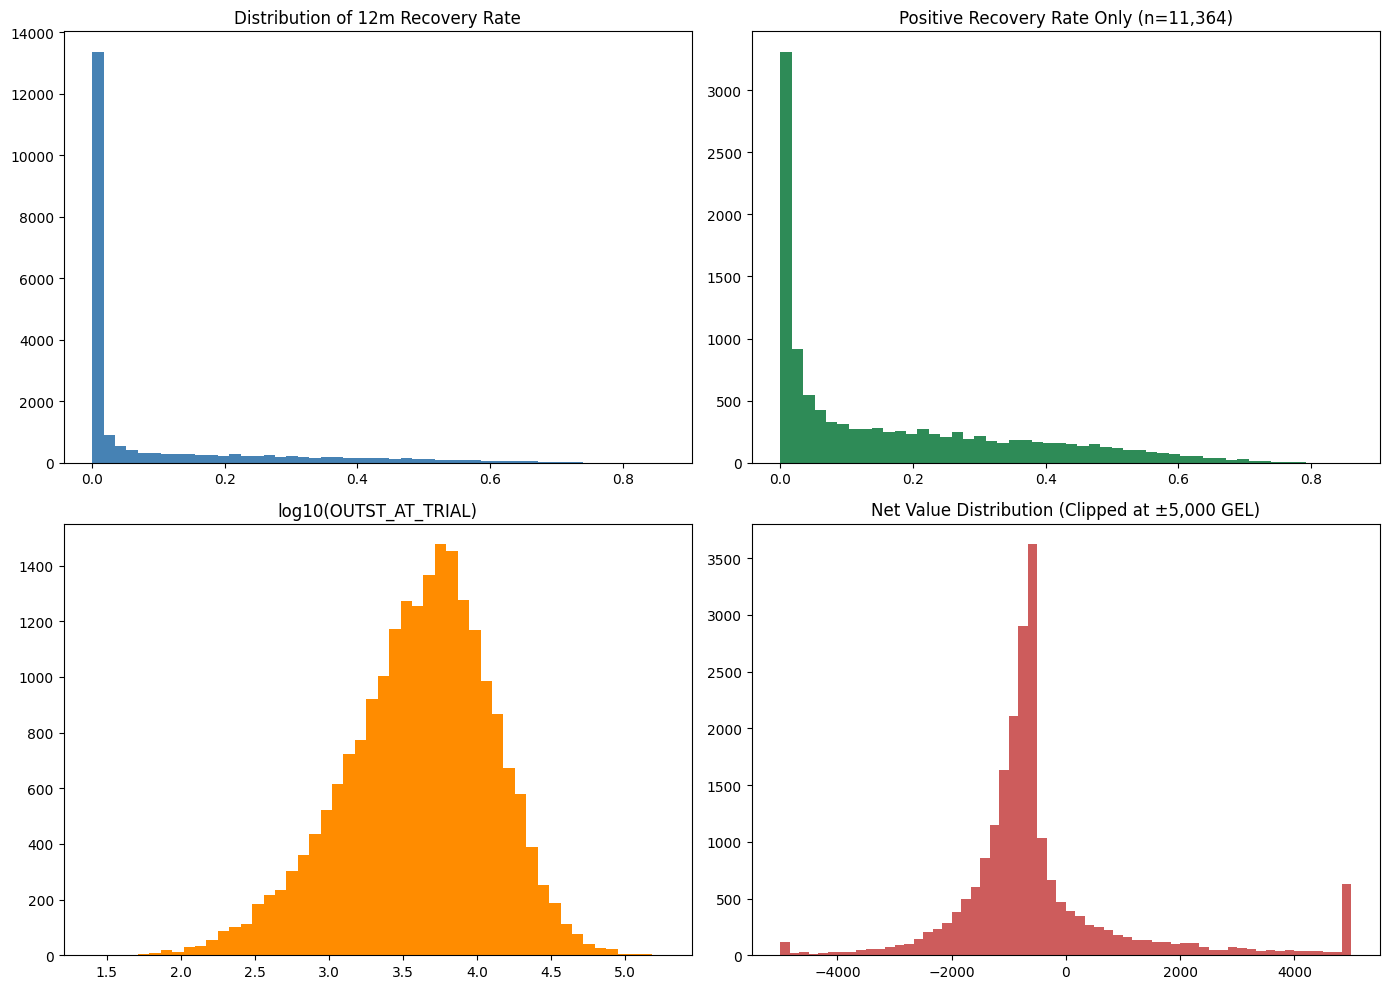

--- Profitability Metrics by Outstanding Balance Quantiles (8 Bins) ---
                          n  avg_rate  profitable  avg_net    total_net
outst_bin                                                              
(25.189, 1026.765]     2678     0.108       0.026 -468.385 -1254335.518
(1026.765, 1982.673]   2678     0.092       0.118 -457.266 -1224559.012
(1982.673, 3086.846]   2678     0.094       0.185 -420.139 -1125131.407
(3086.846, 4470.89]    2678     0.087       0.205 -416.103 -1114325.099
(4470.89, 6256.471]    2678     0.086       0.227 -392.189 -1050283.413
(6256.471, 8882.285]   2678     0.084       0.226 -367.053  -982969.238
(8882.285, 14098.45]   2679     0.083       0.238 -334.419  -895908.334
(14098.45, 180542.79]  2677     0.086       0.254   36.343    97290.464

--- Quarterly Dynamics and Temporal Stability ---
            n  avg_rate  zero_share  profitable
quarter                                        
2023Q1   1386     0.095       0.461       0.202
2023Q2   1452

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))


axes[0, 0].hist(model_df['recovery_rate_12'], bins=50, color='steelblue')
axes[0, 0].set_title('Distribution of 12m Recovery Rate')


pos = model_df[model_df['recovery_rate_12'] > 0]['recovery_rate_12']
axes[0, 1].hist(pos, bins=50, color='seagreen')
axes[0, 1].set_title(f'Positive Recovery Rate Only (n={len(pos):,})')


axes[1, 0].hist(
    np.log10(model_df['OUTST_AT_TRIAL']), bins=50, color='darkorange'
)
axes[1, 0].set_title('log10(OUTST_AT_TRIAL)')


axes[1, 1].hist(
    model_df['net_value'].clip(-5000, 5000), bins=60, color='indianred'
)
axes[1, 1].set_title('Net Value Distribution (Clipped at ±5,000 GEL)')

plt.tight_layout()
plt.show()


model_df['outst_bin'] = pd.qcut(model_df['OUTST_AT_TRIAL'], 8)
print('--- Profitability Metrics by Outstanding Balance Quantiles (8 Bins) ---')
print(
    model_df.groupby('outst_bin', observed=True)
    .agg(
        n=('net_value', 'size'),
        avg_rate=('recovery_rate_12', 'mean'),
        profitable=('is_profitable', 'mean'),
        avg_net=('net_value', 'mean'),
        total_net=('net_value', 'sum'),
    )
    .round(3)
)


model_df['quarter'] = (
    pd.to_datetime(model_df['PERIOD'], format='%Y/%m').dt.to_period('Q').astype(str)
)
print('\n--- Quarterly Dynamics and Temporal Stability ---')
print(
    model_df.groupby('quarter')
    .agg(
        n=('net_value', 'size'),
        avg_rate=('recovery_rate_12', 'mean'),
        zero_share=('rec_12', lambda s: (s == 0).mean()),
        profitable=('is_profitable', 'mean'),
    )
    .round(3)
)

In [28]:
# merge
feat = features.drop(columns=['feature_045'])  # leakage
df = model_df.merge(
    feat, left_on=['CLIENT_KEY', 'PERIOD'], right_on=['client_key', 'PERIOD'], how='left'
).drop(columns=['client_key'])

feat_cols = [c for c in df.columns if c.startswith('feature_')]
print('shape:', df.shape, '| feature:', len(feat_cols))
print('rows left after merge:', df['feature_001'].isna().sum())

# AUC
y_pos = (df['rec_12'] > 0).astype(int)
rows = []
for c in feat_cols:
    x = df[c].fillna(df[c].median())
    rows.append({
        'feature': c,
        'auc_pos': roc_auc_score(y_pos, x),
        'spearman_rate': df[[c, 'recovery_rate_12']].corr(method='spearman').iloc[0, 1],
    })
uni = pd.DataFrame(rows)
uni['strength'] = (uni['auc_pos'] - 0.5).abs()
uni = uni.merge(fdict[['column', 'group', 'description']], left_on='feature', right_on='column').drop(columns='column')

pd.set_option('display.max_colwidth', 70)
print(uni.sort_values('strength', ascending=False).head(20).round(3).to_string(index=False))
print()
print('average strength acording to groups:')
print(uni.groupby('group')['strength'].mean().sort_values(ascending=False).round(3))

shape: (21424, 86) | feature: 49
rows left after merge: 0
    feature  auc_pos  spearman_rate  strength                            group                                                                               description
feature_031    0.570          0.157     0.070            credit bureau history                               Credit bureau score at the last refresh before enforcement.
feature_034    0.570          0.155     0.070            credit bureau history                Internal behavioural score at the last monthly refresh before enforcement.
feature_019    0.441         -0.136     0.059 repayment history on other loans                         Share of scheduled instalments paid late over the last 12 months.
feature_012    0.553          0.117     0.053                 account balances                           Maximum end-of-day total balance across all accounts, 6 months.
feature_021    0.449         -0.112     0.051 repayment history on other loans                   

In [29]:
desc = df[feat_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
desc['skew'] = df[feat_cols].skew()
desc['n_unique'] = df[feat_cols].nunique()

print("=== Step 3: Feature Summary Statistics & Distributions ===")
print(
    desc[['min', '1%', '50%', '99%', 'max', 'skew', 'n_unique']]
    .round(2)
    .to_string()
)

print("\n--- Detailed Breakdown: feature_023 ---")
print("Share of feature_023 > 1:", (df['feature_023'] > 1).mean().round(3))
print(
    df.groupby(
        pd.qcut(df['feature_023'], 5, duplicates='drop'), observed=True
    )
    .agg(
        n=('rec_12', 'size'),
        pos_rate=('rec_12', lambda s: (s > 0).mean()),
        avg_rate=('recovery_rate_12', 'mean'),
    )
    .round(3)
)

print("\n=== Step 4: Missing Values Impact on Target Variables ===")
for c in ['feature_011', 'feature_039']:
    m = df[c].isna()
    print(f"\n--- Feature: {c} (NaN Share = {m.mean():.3f}) ---")
    print(
        df.groupby(m)
        .agg(
            n=('rec_12', 'size'),
            pos_rate=('rec_12', lambda s: (s > 0).mean()),
            avg_rate=('recovery_rate_12', 'mean'),
            avg_outst=('OUTST_AT_TRIAL', 'mean'),
        )
        .round(3)
    )

=== Step 3: Feature Summary Statistics & Distributions ===
                min      1%      50%       99%        max   skew  n_unique
feature_001    0.00    0.00     2.00      9.00      18.00   1.53        19
feature_002    0.00    0.00     4.00     15.00      32.00   1.04        27
feature_003    2.41   15.28   167.10   2023.69    8548.12   5.38     17527
feature_004    1.79   52.88  1377.42  33251.50  265437.76  10.76     20890
feature_005    0.00    0.00     2.00      7.00      13.00   1.09        14
feature_006    0.00    0.03     0.33      0.83       0.97   0.44      7141
feature_007    1.04    6.40    59.00    608.83    2442.40   5.13     12732
feature_008    0.00    0.00     1.00      6.00      11.00   1.32        12
feature_009    0.00    3.00    18.00     51.00      94.00   0.95        79
feature_010   10.55  100.01  1480.21  24059.38  237984.90   9.65     20915
feature_011    5.20   13.04    98.52    805.44    2098.06   4.15      2788
feature_012    0.04    0.71    31.02   12

In [30]:
print(
    'Equality Share (feature_017 == feature_033):',
    (df['feature_017'] == df['feature_033']).mean().round(3),
)


use = [c for c in feat_cols if c != 'feature_050']
corr = df[use].corr(method='spearman')
pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .rename('rho')
    .reset_index()
)
pairs.columns = ['f1', 'f2', 'rho']

print('\n--- Highly Correlated Pairs (|rho| > 0.7) ---')
print(
    pairs[pairs['rho'].abs() > 0.7]
    .sort_values('rho', key=abs, ascending=False)
    .round(3)
    .to_string(index=False)
)

early = df['PERIOD'] < '2025/01'
drift = []

for c in use:
    a, b = df.loc[early, c].dropna(), df.loc[~early, c].dropna()
    drift.append({
        'feature': c,
        'median_early': a.median(),
        'median_late': b.median(),
        'shift_in_std': (b.mean() - a.mean()) / df[c].std(),
    })

drift_df = pd.DataFrame(drift)

print('--- Features with Significant Temporal Shift (|shift_in_std| > 0.1) ---')
print(
    drift_df[drift_df['shift_in_std'].abs() > 0.1]
    .round(3)
    .to_string(index=False)
)
print(
    '\nTotal Features with Shift > 0.1 std:',
    (drift_df['shift_in_std'].abs() > 0.1).sum(),
)

Equality Share (feature_017 == feature_033): 1.0

--- Highly Correlated Pairs (|rho| > 0.7) ---
         f1          f2   rho
feature_017 feature_033 1.000
feature_003 feature_007 0.930
feature_031 feature_034 0.924
--- Features with Significant Temporal Shift (|shift_in_std| > 0.1) ---
    feature  median_early  median_late  shift_in_std
feature_007         54.61       69.365         0.189

Total Features with Shift > 0.1 std: 1


In [31]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="eda_and_feature_discovery"):

    mlflow.log_param("dropped_leakage_features", ["feature_045"])
    mlflow.log_param("total_features_evaluated", len(feat_cols))
    mlflow.log_param("high_corr_threshold", 0.7)
    mlflow.log_param("drift_std_threshold", 0.1)


    high_corr_count = len(pairs[pairs['rho'].abs() > 0.7])
    drift_count = (drift_df['shift_in_std'].abs() > 0.1).sum()
    top_feature = uni.sort_values('strength', ascending=False).iloc[0]

    mlflow.log_metric("high_correlated_pairs_count", high_corr_count)
    mlflow.log_metric("drifted_features_count", drift_count)
    mlflow.log_metric("top_feature_auc_pos", round(top_feature['auc_pos'], 4))
    mlflow.log_metric("top_feature_spearman", round(top_feature['spearman_rate'], 4))


    group_strength = uni.groupby('group')['strength'].mean()
    for grp_name, val in group_strength.items():
        mlflow.log_metric(f"avg_strength_group_{grp_name}", round(val, 4))


    fig.savefig("eda_target_and_outst_distributions.png", bbox_inches='tight', dpi=150)
    mlflow.log_artifact("eda_target_and_outst_distributions.png")
    plt.close(fig)


    uni_sorted = uni.sort_values('strength', ascending=False)
    uni_sorted.to_csv("univariate_feature_power.csv", index=False)
    mlflow.log_artifact("univariate_feature_power.csv")


    pairs[pairs['rho'].abs() > 0.7].to_csv("highly_correlated_feature_pairs.csv", index=False)
    mlflow.log_artifact("highly_correlated_feature_pairs.csv")


    drift_df[drift_df['shift_in_std'].abs() > 0.1].to_csv("temporal_drift_features.csv", index=False)
    mlflow.log_artifact("temporal_drift_features.csv")

print(" `eda_and_feature_discovery` run successfully logged with plots & CSV artifacts!")

🏃 View run eda_and_feature_discovery at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/f6f7bac57f7f45afaf8c91028b1c5222
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 `eda_and_feature_discovery` run successfully logged with plots & CSV artifacts!


 **EDA Analysis**

მონაცემების გაერთიანებისა (Merge) და 50-ვე ცვლადის დეტალური ანალიზის შემდეგ, EDA-ს ეტაპი სრულყოფილად დავასრულეთ. გაერთიანება მოხდა 100%-იანი სიზუსტით, ყოველგვარი დანაკარგის გარეშე (21,424 ეპიზოდი). წინასწარი ეჭვის საფუძველზე სრულად ამოვიღეთ feature_045, რადგან ის სასამართლოს დაწყების შემდგომ 12 თვეს აღწერდა და Data Leakage-ს გამოიწვევდა.

Leakage-ის შემოწმებამ დარჩენილ ცვლადებზე აჩვენა, რომ ერთცვლადიანი AUC (სამიზნეზე: rec_12 > 0) მაქსიმუმ 0.570-ს აღწევს (feature_031 და feature_034), რაც საეჭვო ზღვარს (0.75) ბევრად ჩამოუვარდება. ეს ადასტურებს, რომ მონაცემებში მომავლის ინფორმაცია გაჟონილი არ არის.

ცალკეული ცვლადები საპროგნოზოდ საკმაოდ სუსტია (AUC 0.55–0.57). ყველაზე გამოსადეგი და რეალური სიგნალი წამოვიდა კლიენტის გადახდების ისტორიიდან, საკრედიტო ბიუროს სკორიდან და ანგარიშებზე არსებული ფულადი ნაშთებიდან. ხოლო ისეთი მონაცემები, ვიყენებთ თუ არა მობილბანკს (ციფრულ არხებს) ან რამდენად ხშირად ვირჩევდით ახალ სესხებს ბოლო დროს, თითქმის უსარგებლო აღმოჩნდა. ამის გამო, თავად მოდელის შედეგებიც ზომიერი იქნება და პროექტის მთავარი ეკონომიკური ეფექტი ნაწილობრივ ბალანსის სწორი წესიდან მოვა (მაგალითად, ზედა ოქტილში >14k ₾ სესხებზე ფოკუსირება იძლევა +0.10 მლნ ₾-ს, მაშინ როცა ბრმად "ყველასთვის უჩივლე" სტრატეგიას −7.55 მლნ ₾ ზარალზე გადაჰყავს ბანკი).

ცვლადების ლოგიკა ეკონომიკურად გამართულია: უკეთესი ბიუროსა და შიდა სკორი, მაღალი შემოსავალი და ნაშთები ზრდის ამოღების შანსს, ხოლო დაგვიანებები, 30+ დღიანი ვადაგადაცილებები და რესტრუქტურიზაციები ამცირებს მას. გამონაკლისია feature_018 — ერთი შეხედვით, რაც მეტი ვალები აქვს კლიენტს, მით ნაკლები უნდა გადაიხადოს, მაგრამ აქ პირიქითაა: თუ კლიენტს ბანკში რამდენიმე აქტიური სესხი/პროდუქტი აქვს, ბანკს მასზე ზემოქმედების გაცილებით მეტი ბერკეტი გააჩნია (მაგ. სხვა ანგარიშებიდან ჩამოჭრა, აქტიური კომუნიკაცია), რის გამოც ფულის ამოღება უკეთესად ხდება. ასევე, feature_023 (სხვა სესხებზე ინსტალმენტების გადახდის უფრო მაღალი წილი) მონოტონურად უარყოფითად უკავშირდება ამოღებას — თითქოს ვისაც სესხის მეტი ნაწილი უკვე გადახდილი აქვს, იმან დარჩენილიც უნდა გადაიხადოს, თუმცა მონაცემები საპირისპიროს აჩვენებს. ამ ცვლადს ვინახავთ და მიზეზს მოგვიანებით SHAP analysis-ით გადავამოწმებთ.

გამოტოვებული მონაცემების (NaN) ანალიზმა ძალიან საინტერესო რამ დაგვანახა: თვითონ ის ფაქტი, უწერია თუ არა კლიენტს მონაცემი, უკვე ძლიერი მინიშნებაა. კლიენტებს, რომლებსაც დეპოზიტი უფიქსირდებათ (feature_011 არ არის გამოტოვებული), ვალის გადახდის 64.1%-იანი შანსი აქვთ (საშუალო recovery rate 13.9%), მაშინ როცა დეპოზიტის გარეშე ეს შანსი 51.3%-მდე ეცემა (rate 8.2%). საპირისპიროდ, თუ კლიენტს შემოსავალი საერთოდ არ უწერია (feature_039 არის NaN — სავარაუდოდ, ანკეტა საერთოდ არ არსებობს), თანხის დაბრუნების შანსი 44.2%-მდე ეცემა (rate 5.6%). რადგან ორივე ჯგუფში სესხის საშუალო ნაშთი ზუსტად ერთი და იგივეა (~7,050 ₾), დავრწმუნდით, რომ ეს განსხვავება სესხის სიდიდით კი არ არის გამოწვეული, არამედ თვითონ მონაცემის არსებობა-არარსებობით. სწორედ ამიტომ, Preprocessing-ისთვის შევქმენით ორი ახალი ინდიკატორი: has_deposit და income_missing.

განაწილებების მხრივ, ფულადი ცვლადები ძლიერ მარჯვნივ არის დახრილი (Skew 5–14). feature_05 ამოვიღეთ, რადგან კონსტანტა იყო (ყველა = 1), ხოლო feature_030 თითქმის მთლიანად ნულოვანია. მულტიკოლინეარობის შემოწმებისას აღმოჩნდა, რომ feature_017 და feature_033 აღწერილობით სხვადასხვა წყაროა, თუმცა მონაცემებში 100%-ით იდენტური გამოდგა, რის გამოც 033 ამოვიღეთ. ასევე ძალიან მაღალი კორელაცია გამოვლინდა 003/007-სა (ρ=0.93) და 031/034-ს (ρ=0.92) შორის.

დროითი სტაბილურობის (Drift) ანალიზმა 2023–24 და 2025 წლებს შორის აჩვენა, რომ 46 ცვლადიდან საშუალოს ცვლილების მიხედვით მხოლოდ feature_007 გადაიხარა (მედიანა გაიზარდა +27%-ით, 0.19 std), რის გამოც ეს ცვლადი საბოლოოდ ამოვიღეთ. დანარჩენი ცვლადები დროში სტაბილურია, რაც კიდევ ერთხელ ადასტურებს Time-based Data Split-ის მართებულობას (ხოლო feature_007-ს შემდგომში PSI მონიტორინგში დავამატებთ).

მოკლედ რომ შევაჯამოთ, EDA-ს შედეგად ჩამოვყალიბდი საბოლოო სტრატეგიაზე: მოდელირებამდე, Preprocessing-ის ეტაპზე, სულ 4 ზედმეტი ცვლადის ამოღებას ვაპირებ: 045 (მომავლის გაჟონვის გამო), 050 (მხოლოდ 1-იანები წერია), 033 (დუბლიკატი) და 007 (მაღალი კორელაციისა და დრიფტის გამო). სანაცვლოდ, მოდელისთვის გამოვიყენებ 5 ახალ სასარგებლო ნიშნაკს: has_deposit, income_missing, has_secured_loan, `n_unsec_loans` და OUTST_AT_TRIAL. უშუალოდ მონაცემების დამუშავებისას (Train/Test Split-ის შემდეგ), ხეებზე დაფუძნებული მოდელებისთვის (XGBoost) გამოტოვებულ ადგილებს (NaN) პირდაპირ ისე დავტოვებთ, როგორც არის. ხოლო ლოგისტიკური რეგრესიისთვის გამოვიყენებთ მხოლოდ Train-ზე დათვლილ მედიანებს, ფულად ცვლადებს ლოგარითმით გავასწორებთ (log1p) და სტანდარტულ მასშტაბზე გადავიყვანთ.

**preprocessing**

In [31]:
sec = (
    loans.groupby(['CLIENT_KEY', 'PERIOD'])['HAS_COLLATERAL']
    .max()
    .rename('has_secured_loan')
    .reset_index()
)
df = df.merge(sec, on=['CLIENT_KEY', 'PERIOD'], how='left')

df['has_deposit'] = df['feature_011'].notna().astype(int)
df['income_missing'] = df['feature_039'].isna().astype(int)
df['feature_011'] = df['feature_011'].fillna(0)

drop_feats = ['feature_050', 'feature_033', 'feature_007']
model_feats = [c for c in feat_cols if c not in drop_feats] + [
    'has_deposit',
    'income_missing',
    'has_secured_loan',
    'n_unsec_loans',
    'OUTST_AT_TRIAL',
]


print("Total Final Model Features:", len(model_feats))


df['split'] = np.where(
    df['PERIOD'] <= '2024/06',
    'train',
    np.where(df['PERIOD'] <= '2024/12', 'valid', 'test'),
)

train_clients = set(df.loc[df['split'] == 'train', 'CLIENT_KEY'])
valid_clients = set(df.loc[df['split'] == 'valid', 'CLIENT_KEY'])

ov_valid = df['CLIENT_KEY'].isin(train_clients) & (df['split'] == 'valid')
ov_test = df['CLIENT_KEY'].isin(train_clients | valid_clients) & (
    df['split'] == 'test'
)

print(
    'Train Clients Overlapping in Validation:',
    ov_valid.sum(),
    '/',
    (df['split'] == 'valid').sum(),
)
print(
    'Train/Valid Clients Overlapping in Test:',
    ov_test.sum(),
    '/',
    (df['split'] == 'test').sum(),
)


df_clean = df[~(ov_valid | ov_test)].copy()

print(
    df_clean.groupby('split')
    .agg(
        n=('rec_12', 'size'),
        clients=('CLIENT_KEY', 'nunique'),
        zero_share=('rec_12', lambda s: (s == 0).mean()),
        avg_rate=('recovery_rate_12', 'mean'),
        profitable=('is_profitable', 'mean'),
        net_all=('net_value', 'sum'),
    )
    .round(3)
)

Total Final Model Features: 51
Train Clients Overlapping in Validation: 898 / 4530
Train/Valid Clients Overlapping in Test: 1772 / 6750
           n  clients  zero_share  avg_rate  profitable      net_all
split                                                               
test    4978     4617       0.469     0.088       0.182 -1770779.170
train  10144     9298       0.463     0.094       0.192 -3250262.008
valid   3632     3485       0.474     0.086       0.174 -1401856.616


In [34]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="preprocessing_and_split"):
    mlflow.log_param("total_model_features", len(model_feats))
    mlflow.log_param("dropped_features", drop_feats)
    mlflow.log_param("train_cutoff", "2024/06")
    mlflow.log_param("valid_cutoff", "2024/12")


    mlflow.log_metric("overlap_valid_clients_removed", int(ov_valid.sum()))
    mlflow.log_metric("overlap_test_clients_removed", int(ov_test.sum()))


    split_summary = df_clean.groupby('split').agg(
        n=('rec_12', 'size'),
        clients=('CLIENT_KEY', 'nunique'),
        zero_share=('rec_12', lambda s: (s == 0).mean()),
        avg_rate=('recovery_rate_12', 'mean'),
        profitable=('is_profitable', 'mean'),
        net_all=('net_value', 'sum')
    ).round(3)

    for split_name in ['train', 'valid', 'test']:
        if split_name in split_summary.index:
            row = split_summary.loc[split_name]
            mlflow.log_metric(f"{split_name}_sample_size", int(row['n']))
            mlflow.log_metric(f"{split_name}_unique_clients", int(row['clients']))
            mlflow.log_metric(f"{split_name}_zero_recovery_share", float(row['zero_share']))
            mlflow.log_metric(f"{split_name}_avg_recovery_rate", float(row['avg_rate']))
            mlflow.log_metric(f"{split_name}_profitable_share", float(row['profitable']))
            mlflow.log_metric(f"{split_name}_total_net_value", float(row['net_all']))


    split_summary.reset_index().to_csv("dataset_split_summary.csv", index=False)
    mlflow.log_artifact("dataset_split_summary.csv")

print(" `preprocessing_and_split` run successfully logged to MLflow!")

🏃 View run preprocessing_and_split at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/721ea4a04aa64253b4518c8ba5c58129
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 `preprocessing_and_split` run successfully logged to MLflow!


**preprocessing analysis**

მონაცემები დავყავით დროის მიხედვით, რაც რეალურ გამოყენებას უახლოვდება: წარსულით ვსწავლობთ, მომავალს ვაფასებთ. Train (2023/01 – 2024/06): 10,144 ეპიზოდი (9,298 უნიკალური კლიენტი) Validation (2024/07 – 2024/12): 3,632 ეპიზოდი Test (2025/01 – 2025/08): 4,978 ეპიზოდი.
ერთი კლიენტი რამდენიმე ეპიზოდში გვხვდება. იმისთვის, რომ მოდელმა კონკრეტული კლიენტი კი არ დაიმახსოვროს, არამედ ზოგადი კანონზომიერება ისწავლოს (და შეფასება ხელოვნურად არ გაიზარდოს), Validation-იდან ამოვიღეთ ის ეპიზოდები, რომელთა კლიენტიც Train-ში გვხვდება (898 / 4,530 = 19.8%), ხოლო Test-იდან ისინი, რომელთა კლიენტიც Train-შიც ან Validation-შიც გვხვდება (1,772 / 6,750 = 26.3%). Train-ში გადაფარვა არ გაგვიწმენდია, ამიტომ cross-validation გვექნება კლიენტის მიხედვით დაჯგუფებული (GroupKFold).

სამივე ნაწილში სამიზნის პროფილი მსგავსია (zero share ~0.46–0.47, avg recovery rate ~0.086–0.094, profitable share ~0.17–0.19). ეს არ ამტკიცებს, რომ ცვლადებსა და სამიზნეს შორის კავშირიც უცვლელია; ამას მოდელის out-of-time შედეგები გვიჩვენებს.
გასუფთავებულ Test-ზე, 2025 წლის მხოლოდ ის ეპიზოდები, სადაც კლიენტი Train-სა და Valid-ში არ გვხვდება, ბრმად ყველა კლიენტისთვის ჩივილის სტრატეგია ბანკს ჯამურად −1.77 მლნ ₾ ზარალს აყენებს (საშუალოდ −356 ₾ თითო საქმეზე), რაც ზუსტად იმასვე აჩვენებს, რასაც მთლიანი მონაცემები.

თუმცა უნდა გავითვალისწინოთ, რომ Test-იდან გამოგდებული განმეორებითი კლიენტები შესაძლოა ჩვეულებრივზე უფრო "ცუდი" გადამხდელები იყვნენ. ამიტომ, მოგვიანებით მოდელს სრულ Test-ზეც (6,750 ეპიზოდზე) შევაფასებთ.

**Training**

მოდელის შეფასება ხდება ორი გზით: ტექნიკურად რამდენად კარგად ისწავლა და რეალურად რა შედეგს მოუტანს ბანკს.

ვიყენებთ ROC-AUC, ზომავს, რამდენად კარგად არჩევს მოდელი გადამხდელსა და არაგადამხდელს — ანუ შემთხვევით არჩეულ გადამხდელს უფრო მაღალ ალბათობას მისცემს თუ არა, ვიდრე არაგადამხდელს. ასვე ეს მეტრიკა არ არის დამოკიდებული threadhold-ზე.

ასევე გამოვიყენებ PR-AUC, რადგან მომგებიანი საქმეები ცოტაა, ეს მეტრიკა უკეთ გვიჩვენებს ვიდრე ROC-AUC, რადგან კარგად იჭერს მოდელი ამ იშვიათ, რეალურად მომგებიან კლიენტებს.

კორელაციას რაც შეეხება გამოვიყენებ Spearman-ის რანგობრივი კორელაციას. ის ზომავს, რამდენად სწორი მიმდევრობით (რიგითობით) ალაგებს მოდელი კლიენტებს ამოღების პროცენტის მიხედვით. რადგან დატაში ბევრი 0-ია და განაწილება დახრილია (Skewed), Spearman-ი Pearson-ზე უმჯობესია. ასევცე გამოვიყენებ MAE (recovery_rate_12-ზე)-ს, რომელიც  გვიჩვენებს საშუალო ცდომილებას პროცენტულ პუნქტებში. ასევე უნდა გავითვლაისწინოთ, რომ მოდელის დაპროგნოზებული ალბათობები/rate-ები ზუსტად უნდა ემთხვეოდეს რეალურ სიხშირეებს. თუ მოდელი ალბათობას გაბერავს, Net Value-ს ლოგიკაც არასწორად დაითვლის მოგებას.

რაც შეეხება ბიზნესურ ვალიდაციას, ვიყენებთ total net value-ს - ჯამური წმინდა მოგება ან ზარალი (ლარებში) იმ კლიენტებზე, რომლებსაც მოდელის რჩევით ვუჩივლებთ. net value per case - საშუალო მოგება თითოეულ ჩივილზე. და Cumulative Profit Curve, რომელიც გვიჩვენებს, თუ როგორ იზრდება ბანკის წმინდა მოგება კლიენტების პროგნოზირებული ქულის მიხედვით გაფილტვრისას.

In [32]:
#Defines financial functions and performance metrics to evaluate
#all models consistently on train, validation, and test sets.
K = 1.405
tr = df_clean[df_clean['split'] == 'train'].reset_index(drop=True)
va = df_clean[df_clean['split'] == 'valid'].reset_index(drop=True)
te = df_clean[df_clean['split'] == 'test'].reset_index(drop=True)

def cost(d):
    return 500 + 0.10 * d['OUTST_AT_TRIAL']

def pred_net(d, rate_pred):
    """forecasted net_value (annualized to 24 months)"""
    return K * d['OUTST_AT_TRIAL'] * rate_pred - cost(d)

def business(d, score, name, thr=0.0):
    """we sue where score > thr"""
    sel = (score > thr).values if hasattr(score, 'values') else (score > thr)
    return {'rule': name, 'n_sued': int(sel.sum()), 'share': round(sel.mean(), 3),
            'net_total': round(d.loc[sel, 'net_value'].sum()),
            'net_per_case': round(d.loc[sel, 'net_value'].mean()) if sel.any() else 0}

def quality(d, p_pos=None, rate=None):
    out = {}
    if p_pos is not None:
        y = (d['rec_12'] > 0).astype(int)
        out['AUC(rec>0)'] = round(roc_auc_score(y, p_pos), 3)
        out['PR-AUC(profit)'] = round(average_precision_score(d['is_profitable'], rate if rate is not None else p_pos), 3)
    if rate is not None:
        out['Spearman(rate)'] = round(spearmanr(rate, d['recovery_rate_12'])[0], 3)
    return out

print('train/valid/test:', len(tr), len(va), len(te))
print('profit base rate (PR-AUC basis):', round(va['is_profitable'].mean(), 3))

train/valid/test: 10144 3632 4978
profit base rate (PR-AUC basis): 0.174


In [36]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="evaluation_framework_setup"):

    mlflow.log_param("k_24_12_multiplier", K)
    mlflow.log_param("fixed_legal_cost_gel", 500)
    mlflow.log_param("variable_legal_cost_pct", 0.10)


    mlflow.log_metric("train_sample_size", len(tr))
    mlflow.log_metric("valid_sample_size", len(va))
    mlflow.log_metric("test_sample_size", len(te))
    mlflow.log_metric("valid_profitable_base_rate", round(float(va['is_profitable'].mean()), 4))
    mlflow.log_metric("valid_pos_recovery_base_rate", round(float((va['rec_12'] > 0).mean()), 4))

print(" Evaluation Framework logic successfully registered in MLflow!")

🏃 View run evaluation_framework_setup at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/fa56237275f640c5a9537a09fdf767ca
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 Evaluation Framework logic successfully registered in MLflow!


**Bottom-line Baseline**

In [33]:
rows = []
for nm, d in [('valid', va), ('test', te)]:
    r = business(d, pd.Series(1.0, index=d.index), '0: sue everyone'); r['set'] = nm; rows.append(r)
    r = business(d, d['OUTST_AT_TRIAL'] - 14098, '1: OUTST>14098'); r['set'] = nm; rows.append(r)
bench = pd.DataFrame(rows)[['set','rule','n_sued','share','net_total','net_per_case']]
print(bench.to_string(index=False))

#Sensitivity: Which balance threshold would be optimal on the validation set (for information only)
for t in [5000, 8000, 10000, 14098, 20000, 30000]:
    s = va['OUTST_AT_TRIAL'] > t
    print(f'OUTST>{t:>6}: n={s.sum():>5}  net={va.loc[s,"net_value"].sum():>10,.0f}')

  set            rule  n_sued  share  net_total  net_per_case
valid 0: sue everyone    3632  1.000   -1401857          -386
valid  1: OUTST>14098     434  0.119     -13404           -31
 test 0: sue everyone    4978  1.000   -1770779          -356
 test  1: OUTST>14098     602  0.121     141082           234
OUTST>  5000: n= 1693  net=  -541,973
OUTST>  8000: n= 1039  net=  -241,444
OUTST> 10000: n=  769  net=  -177,700
OUTST> 14098: n=  434  net=   -13,404
OUTST> 20000: n=  199  net=    48,125
OUTST> 30000: n=   65  net=    39,984


In [38]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="bottomline_baseline"):

    for _, row in bench.iterrows():
        set_name = row['set']
        rule_name = "sue_all" if "0:" in row['rule'] else "outst_gt_14k"

        mlflow.log_metric(f"{set_name}_{rule_name}_n_sued", int(row['n_sued']))
        mlflow.log_metric(f"{set_name}_{rule_name}_share", float(row['share']))
        mlflow.log_metric(f"{set_name}_{rule_name}_net_total_gel", float(row['net_total']))
        mlflow.log_metric(f"{set_name}_{rule_name}_net_per_case_gel", float(row['net_per_case']))


    sens_rows = []
    for t in [5000, 8000, 10000, 14098, 20000, 30000]:
        s = va['OUTST_AT_TRIAL'] > t
        sens_rows.append({
            'threshold_outst_gel': t,
            'n_sued': int(s.sum()),
            'share_sued': round(float(s.mean()), 3),
            'net_total_gel': round(float(va.loc[s, "net_value"].sum()), 0)
        })

    sens_df = pd.DataFrame(sens_rows)
    sens_df.to_csv("outst_sensitivity_validation.csv", index=False)
    mlflow.log_artifact("outst_sensitivity_validation.csv")


    bench.to_csv("baseline_benchmarks_summary.csv", index=False)
    mlflow.log_artifact("baseline_benchmarks_summary.csv")

print(" Baseline Benchmarks successfully logged to MLflow under 'bottomline_baseline'!")

🏃 View run bottomline_baseline at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/8b1d5d6849cb480592609dac494726a9
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 Baseline Benchmarks successfully logged to MLflow under 'bottomline_baseline'!


**Bottom-line Baseline analysis**

ვნახეთ, რომ თუ ყველას ვუჩივლებთ საშინელ ზარალს მივიღებთ. უპირობო სასამართლო დავა უმართავი ხარჯია. თითოეულ საქმეზე ბანკი საშუალოდ 356–386 ₾-ს აგებს, რადგან სასამართლო ხარჯები აჭარბებს დაბალი ამოღების მქონე კლიენტებისგან მიღებულ შემოსავალს. მხოლოდ სესხის ნაშთზე დაფუძნებული წესი მკვეთრად ამცირებს ზარალს (ფილტრავს პორტფელის ~88%-ს), თუმცა არასტაბილურია დროის სხვადასხვა პერიოდში. ის ვერ ითვალისწინებს კლიენტის გადახდისუნარიანობასა და ამოღების რეალურ ალბათობას, რის გამოც Validation პერიოდში მაინც ზარალიანი აღმოჩნდა.

შესაბამისად ვხედავტ, რომ OUTST > X არის ცალმხრივი, ის ეყრდნობა მხოლოდ ვალის სიდიდეს და სრულიად აიგნორებს კლიენტის ქცევით მახასიათებელს.



**LogisticRegression**




In [34]:
money = ['feature_003','feature_004','feature_010','feature_011','feature_012','feature_014',
         'feature_015','feature_016','feature_039','feature_040','OUTST_AT_TRIAL']

def prep_lr(d):
    X = d[model_feats].copy()
    for c in money:
        X[c] = np.log1p(X[c])
    return X.drop(columns=['feature_034'])


# Prepare features and target variables
Xtr, Xva, Xte = prep_lr(tr), prep_lr(va), prep_lr(te)
ytr = (tr['rec_12'] > 0).astype(int)
yva = (va['rec_12'] > 0).astype(int)
yte = (te['rec_12'] > 0).astype(int)
groups = tr['CLIENT_KEY']

def make_lr(C, penalty):
    return make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(
            C=C,
            penalty=penalty,
            solver='liblinear',
            max_iter=2000,
            random_state=42
        )
    )

# GroupKFold to respect client-level independence in train set
gkf = GroupKFold(n_splits=5)
rows = []

for penalty in ['l2', 'l1']:
    for C in [0.001, 0.01, 0.1, 1, 10]:
        cv_auc = []
        for tr_i, te_i in gkf.split(Xtr, ytr, groups):
            m = make_lr(C, penalty).fit(Xtr.iloc[tr_i], ytr.iloc[tr_i])
            cv_auc.append(roc_auc_score(ytr.iloc[te_i], m.predict_proba(Xtr.iloc[te_i])[:, 1]))

        m = make_lr(C, penalty).fit(Xtr, ytr)
        pv = m.predict_proba(Xva)[:, 1]

        rows.append({
            'penalty': penalty,
            'C': C,
            'cv_auc_mean': np.mean(cv_auc),
            'cv_auc_std': np.std(cv_auc),
            'valid_auc': roc_auc_score(yva, pv),
            'valid_logloss': log_loss(yva, pv)
        })

grid = pd.DataFrame(rows).round(4)
print("=== Grid Search Results ===")
print(grid.to_string(index=False))

best = grid.sort_values('valid_auc', ascending=False).iloc[0]
print('\n=== Highest Valid AUC ===\n', best)

=== Grid Search Results ===
penalty      C  cv_auc_mean  cv_auc_std  valid_auc  valid_logloss
     l2  0.001       0.7553      0.0140     0.7365         0.5901
     l2  0.010       0.7586      0.0121     0.7385         0.5679
     l2  0.100       0.7586      0.0118     0.7383         0.5652
     l2  1.000       0.7585      0.0118     0.7383         0.5652
     l2 10.000       0.7585      0.0118     0.7382         0.5652
     l1  0.001       0.6319      0.0039     0.6388         0.6361
     l1  0.010       0.7565      0.0120     0.7368         0.5685
     l1  0.100       0.7594      0.0119     0.7394         0.5641
     l1  1.000       0.7586      0.0118     0.7384         0.5651
     l1 10.000       0.7585      0.0118     0.7383         0.5652

=== Highest Valid AUC ===
 penalty              l1
C                   0.1
cv_auc_mean      0.7594
cv_auc_std       0.0119
valid_auc        0.7394
valid_logloss    0.5641
Name: 7, dtype: object


In [35]:
#Train Final Model with Best Parameters (L1, C=0.1)
BEST_C, BEST_PEN = 0.1, 'l1'

final_lr = make_lr(BEST_C, BEST_PEN).fit(Xtr, ytr)

coefs = pd.Series(final_lr[-1].coef_[0], index=Xtr.columns)
print("=== Top 15 Most Important Features ===")
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15).round(3))

pv = final_lr.predict_proba(Xva)[:, 1]
print('\nFinal Valid AUC:', round(roc_auc_score(yva, pv), 3),
      '| Spearman(rate):', round(spearmanr(pv, va['recovery_rate_12'])[0], 3))

=== Top 15 Most Important Features ===
has_secured_loan    1.922
feature_031         0.356
income_missing     -0.212
feature_012         0.203
feature_019        -0.203
feature_003         0.187
feature_036        -0.143
feature_011         0.129
feature_021        -0.111
feature_006        -0.098
feature_039         0.095
feature_008        -0.074
feature_023        -0.066
feature_020        -0.060
feature_026         0.055
dtype: float64

Final Valid AUC: 0.739 | Spearman(rate): 0.493


In [36]:
groups_map = fdict.set_index('column')['group'].to_dict()
my_added = ['has_deposit','income_missing','has_secured_loan','n_unsec_loans','OUTST_AT_TRIAL']

def valid_auc(cols):
    cols = [c for c in cols if c in Xtr.columns]
    m = make_lr(0.1, 'l1').fit(Xtr[cols], ytr)
    return roc_auc_score(yva, m.predict_proba(Xva[cols])[:, 1])

all_cols = list(Xtr.columns)
print('ყველა ცვლადი:', round(valid_auc(all_cols), 3))
print('ჩემი 5 დამატებული გარეშე:', round(valid_auc([c for c in all_cols if c not in my_added]), 3))
print('მხოლოდ ჩემი 5:', round(valid_auc(my_added), 3))
for g in sorted(set(groups_map.values())):
    gc = [c for c, gg in groups_map.items() if gg == g]
    print(f'ჯგუფის გარეშე [{g}]:', round(valid_auc([c for c in all_cols if c not in gc]), 3),
          '| მხოლოდ ეს ჯგუფი:', round(valid_auc(gc), 3))
for f in my_added:
    print(f'მხოლოდ {f}:', round(valid_auc([f]), 3))

coefs_all = pd.Series(final_lr[-1].coef_[0], index=Xtr.columns)
print('\nნულოვანი კოეფიციენტი (l1-მა გამოაგდო):', (coefs_all == 0).sum(), '/', len(coefs_all))

ყველა ცვლადი: 0.739
ჩემი 5 დამატებული გარეშე: 0.617
მხოლოდ ჩემი 5: 0.691
ჯგუფის გარეშე [account balances]: 0.731 | მხოლოდ ეს ჯგუფი: 0.567
ჯგუფის გარეშე [credit bureau history]: 0.725 | მხოლოდ ეს ჯგუფი: 0.566
ჯგუფის გარეშე [declared income]: 0.737 | მხოლოდ ეს ჯგუფი: 0.529
ჯგუფის გარეშე [digital channel usage]: 0.738 | მხოლოდ ეს ჯგუფი: 0.531
ჯგუფის გარეშე [recent credit applications]: 0.739 | მხოლოდ ეს ჯგუფი: 0.509
ჯგუფის გარეშე [repayment history on other loans]: 0.73 | მხოლოდ ეს ჯგუფი: 0.548
ჯგუფის გარეშე [transaction activity]: 0.736 | მხოლოდ ეს ჯგუფი: 0.537
მხოლოდ has_deposit: 0.529
მხოლოდ income_missing: 0.533
მხოლოდ has_secured_loan: 0.639
მხოლოდ n_unsec_loans: 0.555
მხოლოდ OUTST_AT_TRIAL: 0.526

ნულოვანი კოეფიციენტი (l1-მა გამოაგდო): 8 / 50


In [37]:
cal = pd.DataFrame({'p': pv, 'y': yva})
cal['bin'] = pd.qcut(cal['p'], 10, duplicates='drop')
print(cal.groupby('bin', observed=True).agg(pred=('p', 'mean'), actual=('y', 'mean'), n=('y', 'size')).round(3))

                  pred  actual    n
bin                                
(0.0932, 0.276]  0.224   0.291  364
(0.276, 0.339]   0.309   0.328  363
(0.339, 0.388]   0.364   0.353  363
(0.388, 0.433]   0.410   0.421  363
(0.433, 0.481]   0.458   0.424  363
(0.481, 0.531]   0.507   0.474  363
(0.531, 0.59]    0.559   0.474  363
(0.59, 0.69]     0.634   0.628  363
(0.69, 0.993]    0.861   0.876  363
(0.993, 0.999]   0.996   0.995  364


In [38]:
def top_share_business(d, score, shares=(0.1, 0.2, 0.3, 0.5)):
    order = np.argsort(-np.asarray(score))
    out = []
    for s in shares:
        k = int(len(d) * s)
        sel = d.iloc[order[:k]]
        out.append({'top_share': s, 'n': k, 'net_total': round(sel['net_value'].sum()),
                    'net_per_case': round(sel['net_value'].mean()),
                    'avg_rate': round(sel['recovery_rate_12'].mean(), 3)})
    return pd.DataFrame(out)

print('With a logistics score (valid):')
print(top_share_business(va, pv))
print('\nComparison: Sorted by balance (valid):')
print(top_share_business(va, va['OUTST_AT_TRIAL'].values))

With a logistics score (valid):
   top_share     n  net_total  net_per_case  avg_rate
0        0.1   363      59560           164     0.173
1        0.2   726     399162           550     0.207
2        0.3  1089     507329           466     0.187
3        0.5  1816     200449           110     0.142

Comparison: Sorted by balance (valid):
   top_share     n  net_total  net_per_case  avg_rate
0        0.1   363      15763            43     0.087
1        0.2   726    -153920          -212     0.080
2        0.3  1089    -268484          -247     0.082
3        0.5  1816    -590901          -325     0.080


In [39]:
top20 = np.argsort(-pv)[:int(len(va)*0.2)]
print('ტოპ 20%-ში has_secured_loan=1 წილი:', va.iloc[top20]['has_secured_loan'].mean().round(3))
print('მთლიან valid-ში:', va['has_secured_loan'].mean().round(3))

print(va.groupby('has_secured_loan').agg(
    n=('rec_12','size'),
    pos_rate=('rec_12', lambda s: (s>0).mean()),
    avg_rate=('recovery_rate_12','mean'),
    profitable=('is_profitable','mean'),
    net_per_case=('net_value','mean')).round(3))

for v in [0, 1]:
    m = (va['has_secured_loan'] == v).values
    print(f'\nhas_secured_loan={v}, n={m.sum()}')
    print(top_share_business(va[m].reset_index(drop=True), pv[m]))


for v in [0, 1]:
    m = (va['has_secured_loan'] == v).values
    print(f'AUC has_secured_loan={v}:', round(roc_auc_score(yva[m], pv[m]), 3))

ტოპ 20%-ში has_secured_loan=1 წილი: 0.737
მთლიან valid-ში: 0.147
                     n  pos_rate  avg_rate  profitable  net_per_case
has_secured_loan                                                    
0                 3097     0.445     0.068       0.148      -485.549
1                  535     0.996     0.192       0.325       190.447

has_secured_loan=0, n=3097
   top_share     n  net_total  net_per_case  avg_rate
0        0.1   309     337595          1093     0.214
1        0.2   619     408309           660     0.175
2        0.3   929     328390           353     0.143
3        0.5  1548    -108408           -70     0.109

has_secured_loan=1, n=535
   top_share    n  net_total  net_per_case  avg_rate
0        0.1   53     -11138          -210     0.146
1        0.2  107       3148            29     0.168
2        0.3  160        928             6     0.164
3        0.5  267      37707           141     0.175
AUC has_secured_loan=0: 0.64
AUC has_secured_loan=1: 0.233


In [45]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="logistic_regression + some observations"):

    mlflow.log_param("best_penalty", BEST_PEN)
    mlflow.log_param("best_C", BEST_C)
    mlflow.log_param("zeroed_coefs_count", int((coefs_all == 0).sum()))
    mlflow.log_param("total_features_count", len(coefs_all))


    final_valid_auc = float(roc_auc_score(yva, pv))
    final_spearman = float(spearmanr(pv, va['recovery_rate_12'])[0])

    mlflow.log_metric("cv_auc_mean_best", float(best['cv_auc_mean']))
    mlflow.log_metric("cv_auc_std_best", float(best['cv_auc_std']))
    mlflow.log_metric("valid_auc_global", round(final_valid_auc, 4))
    mlflow.log_metric("valid_spearman_global", round(final_spearman, 4))
    mlflow.log_metric("valid_logloss_global", float(best['valid_logloss']))


    m0 = (va['has_secured_loan'] == 0).values
    m1 = (va['has_secured_loan'] == 1).values

    auc_unsec = float(roc_auc_score(yva[m0], pv[m0]))
    auc_sec = float(roc_auc_score(yva[m1], pv[m1]))
    top20_sec_share = float(va.iloc[top20]['has_secured_loan'].mean())

    mlflow.log_metric("auc_subpop_unsecured_has_sec_0", round(auc_unsec, 4))
    mlflow.log_metric("auc_subpop_secured_has_sec_1", round(auc_sec, 4))
    mlflow.log_metric("top20_secured_share_bias", round(top20_sec_share, 4))


    mlflow.log_metric("auc_all_features", round(valid_auc(all_cols), 4))
    mlflow.log_metric("auc_without_custom_5", round(valid_auc([c for c in all_cols if c not in my_added]), 4))
    mlflow.log_metric("auc_only_custom_5", round(valid_auc(my_added), 4))

    for f in my_added:
        mlflow.log_metric(f"auc_only_feature_{f}", round(valid_auc([f]), 4))


    grid.to_csv("logreg_grid_search_results.csv", index=False)
    mlflow.log_artifact("logreg_grid_search_results.csv")


    coef_df = pd.DataFrame({'feature': coefs_all.index, 'coefficient': coefs_all.values})
    coef_df['abs_coef'] = coef_df['coefficient'].abs()
    coef_df.sort_values('abs_coef', ascending=False).to_csv("logreg_coefficients.csv", index=False)
    mlflow.log_artifact("logreg_coefficients.csv")


    cal_summary = cal.groupby('bin', observed=True).agg(
        pred=('p', 'mean'), actual=('y', 'mean'), n=('y', 'size')
    ).reset_index()
    cal_summary.to_csv("logreg_calibration_table.csv", index=False)
    mlflow.log_artifact("logreg_calibration_table.csv")


    biz_score = top_share_business(va, pv)
    biz_score['strategy'] = 'logistic_score'
    biz_outst = top_share_business(va, va['OUTST_AT_TRIAL'].values)
    biz_outst['strategy'] = 'outst_balance'

    biz_comp = pd.concat([biz_score, biz_outst], ignore_index=True)
    biz_comp.to_csv("logreg_business_top_shares.csv", index=False)
    mlflow.log_artifact("logreg_business_top_shares.csv")

print(" `logreg_global_baseline` successfully logged to MLflow with grid results, ablation metrics, and collapse indicators!")

🏃 View run logistic_regression + some observations at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/78d5cab9b0ee4720af734c9c962a0b30
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 `logreg_global_baseline` successfully logged to MLflow with grid results, ablation metrics, and collapse indicators!


**LogisticRegression analysis**

ლოგისტიკური რეგრესიის მოდელმა პირველად შეფასებაზე აჩვენა მაღალი შედეგები (Validation AUC = 0.739; Top 20% პორტფელზე +399 ათასი ₾ მოგება). თუმცა, კოეფიციენტებისა და სეგმენტურ ქცევაზე დაკვირვებით აღმოვაჩინეთ კრიტიკული კანონზომიერება. მოდელის მაღალი სიზუსტე ძირითადად მოდიოდა ერთადერთი ცვლადიდან — has_secured_loan-დან. შერეულ ეპიზოდებში კლიენტების 99.6% 12 თვეში იხდიდნენ. წმინდა არაუზრველყოფილ ეპიზოდში გადამხდელთა წილი მხოლოდ 44.5%-ია. შერეულ ეპიზოდებში დაფიქსირებული ამოღება სავარაუდოდ უკავშირდება არაუზრუნველყოფილი სესხის ავტომატურ დაფარვას უზრუნველყოფის (ქონების რეალიზაცია, დეპოზიტი) ხარჯზე და არა კლიენტის ნებაყოფლობით ქცევას.

იმისათვის რომ მოდელმა არ დაიზეპიროს ეს მარტივი წესი და შეძლოს მართლა კლიენტის რეალური ქცევის სწავლა გადავწყვიტე, რომ პოპულაცია გავყო ორ ნაწილად. პირველი იქნება წმინდა არაუზრუნველყოფილი ნაწილი. მთავარი სამიზნე პოპულაცია. მოდელი აიგება მხოლოდ ამ კლიენტებზე. აქ ლოგისტიკური რეგრესიის რეალური AUC არის 0.640, ხოლო Top 20% ქულით შერჩევა იძლევა +408,309 ₾-ის რეალურ მოგებას.
მეორე ნაწილი კი იქნება შერეული, რადგან ამოღების მაჩვენებელი თითქმის დეტერმინისტულია (99.6%), ამ ჯგუფს მოდელი არ მართავს და გადაეცემა ბიზნესს/უზრუნველყოფის მართვის დეპარტამენტს არსებული შიდა წესებით ასათვისებლად.



**after split bottom line baseline + logistic regression**

In [40]:
A = df_clean[df_clean['has_secured_loan'] == 0].copy()
tr = A[A['split']=='train'].reset_index(drop=True)
va = A[A['split']=='valid'].reset_index(drop=True)
te = A[A['split']=='test'].reset_index(drop=True)

print('train/valid/test:', len(tr), len(va), len(te))
for nm, d in [('train',tr),('valid',va),('test',te)]:
    print(nm, 'pos_rate:', round((d['rec_12']>0).mean(),3),
          '| avg_rate:', round(d['recovery_rate_12'].mean(),3),
          '| profitable:', round(d['is_profitable'].mean(),3),
          '| net_all:', round(d['net_value'].sum()))

# bottom line baseline on segment A
for nm, d in [('valid', va), ('test', te)]:
    for t in [0, 5000, 10000, 14098, 20000]:
        s = d['OUTST_AT_TRIAL'] > t
        print(f'{nm} OUTST>{t:>6}: n={s.sum():>5} net={d.loc[s,"net_value"].sum():>10,.0f}')

train/valid/test: 8698 3097 4252
train pos_rate: 0.461 | avg_rate: 0.079 | profitable: 0.171 | net_all: -3542752
valid pos_rate: 0.445 | avg_rate: 0.068 | profitable: 0.148 | net_all: -1503746
test pos_rate: 0.452 | avg_rate: 0.073 | profitable: 0.16 | net_all: -1981192
valid OUTST>     0: n= 3097 net=-1,503,746
valid OUTST>  5000: n= 1540 net=  -709,179
valid OUTST> 10000: n=  726 net=  -278,881
valid OUTST> 14098: n=  408 net=   -81,436
valid OUTST> 20000: n=  185 net=    12,404
test OUTST>     0: n= 4252 net=-1,981,192
test OUTST>  5000: n= 2075 net=  -886,890
test OUTST> 10000: n=  963 net=  -307,871
test OUTST> 14098: n=  561 net=   -93,233
test OUTST> 20000: n=  276 net=    -4,353


In [41]:
feats_A = [c for c in model_feats if c != 'has_secured_loan']

def prep_lr_A(d):
    X = d[feats_A].copy()
    for c in money:
        X[c] = np.log1p(X[c])
    return X.drop(columns=['feature_034'])

Xtr, Xva, Xte = prep_lr_A(tr), prep_lr_A(va), prep_lr_A(te)
ytr, yva, yte = [(d['rec_12'] > 0).astype(int) for d in (tr, va, te)]
groups = tr['CLIENT_KEY']

rows = []
for penalty in ['l2', 'l1']:
    for C in [0.001, 0.01, 0.1, 1]:
        cv = []
        for a, b in GroupKFold(5).split(Xtr, ytr, groups):
            m = make_lr(C, penalty).fit(Xtr.iloc[a], ytr.iloc[a])
            cv.append(roc_auc_score(ytr.iloc[b], m.predict_proba(Xtr.iloc[b])[:, 1]))
        m = make_lr(C, penalty).fit(Xtr, ytr)
        pv = m.predict_proba(Xva)[:, 1]
        rows.append({'penalty': penalty, 'C': C, 'cv_auc': np.mean(cv), 'cv_std': np.std(cv),
                     'valid_auc': roc_auc_score(yva, pv), 'valid_logloss': log_loss(yva, pv)})
grid = pd.DataFrame(rows).round(4)
print(grid.to_string(index=False))

best = grid.sort_values('valid_auc', ascending=False).iloc[0]
final_lr = make_lr(best['C'], best['penalty']).fit(Xtr, ytr)
pv = final_lr.predict_proba(Xva)[:, 1]
coefs = pd.Series(final_lr[-1].coef_[0], index=Xtr.columns)
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).round(3))

print(top_share_business(va, pv, shares=(0.05, 0.1, 0.2, 0.3, 0.5)))

penalty     C  cv_auc  cv_std  valid_auc  valid_logloss
     l2 0.001  0.6685  0.0046     0.6376         0.6576
     l2 0.010  0.6717  0.0065     0.6388         0.6571
     l2 0.100  0.6713  0.0071     0.6384         0.6579
     l2 1.000  0.6712  0.0071     0.6383         0.6580
     l1 0.001  0.5000  0.0000     0.5000         0.6931
     l1 0.010  0.6697  0.0054     0.6363         0.6585
     l1 0.100  0.6727  0.0066     0.6399         0.6568
     l1 1.000  0.6714  0.0071     0.6385         0.6579
feature_031       0.358
income_missing   -0.212
feature_019      -0.204
feature_012       0.204
feature_003       0.192
feature_036      -0.143
feature_011       0.129
feature_021      -0.111
feature_006      -0.098
feature_039       0.096
feature_008      -0.075
feature_023      -0.066
dtype: float64
   top_share     n  net_total  net_per_case  avg_rate
0       0.05   154     297464          1932     0.267
1       0.10   309     340002          1100     0.214
2       0.20   619     415699  

In [42]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="bottomline_baseline_segA"):


    mlflow.log_metric("train_sample_size", len(tr))
    mlflow.log_metric("valid_sample_size", len(va))
    mlflow.log_metric("test_sample_size", len(te))

    mlflow.log_metric("valid_pos_rate", round(float((va['rec_12']>0).mean()), 4))
    mlflow.log_metric("valid_profitable_share", round(float(va['is_profitable'].mean()), 4))
    mlflow.log_metric("valid_total_net_value_sue_all", round(float(va['net_value'].sum()), 2))

    mlflow.log_metric("test_pos_rate", round(float((te['rec_12']>0).mean()), 4))
    mlflow.log_metric("test_profitable_share", round(float(te['is_profitable'].mean()), 4))
    mlflow.log_metric("test_total_net_value_sue_all", round(float(te['net_value'].sum()), 2))


    sens_rows = []
    for nm, d in [('valid', va), ('test', te)]:
        for t in [0, 5000, 10000, 14098, 20000]:
            s = d['OUTST_AT_TRIAL'] > t
            sens_rows.append({
                'set': nm,
                'outst_threshold_gel': t,
                'n_sued': int(s.sum()),
                'share_sued': round(float(s.mean()), 3),
                'net_total_gel': round(float(d.loc[s, "net_value"].sum()), 0)
            })

    sens_df = pd.DataFrame(sens_rows)
    sens_df.to_csv("segA_outst_sensitivity.csv", index=False)
    mlflow.log_artifact("segA_outst_sensitivity.csv")

print(" `bottomline_baseline_segA` logged successfully!")

🏃 View run bottomline_baseline_segA at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/fb5788ae36904b4aa33ccb9fb1a7e6f2
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 `bottomline_baseline_segA` logged successfully!


In [49]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="logreg_baseline_segA"):

    mlflow.log_param("best_penalty", best['penalty'])
    mlflow.log_param("best_C", best['C'])
    mlflow.log_param("total_features_segA", len(feats_A) - 1) # excluding feature_034

    mlflow.log_metric("cv_auc_mean_best", float(best['cv_auc']))
    mlflow.log_metric("cv_auc_std_best", float(best['cv_std']))
    mlflow.log_metric("valid_auc_segA", float(best['valid_auc']))
    mlflow.log_metric("valid_logloss_segA", float(best['valid_logloss']))


    grid.to_csv("logreg_segA_grid_results.csv", index=False)
    mlflow.log_artifact("logreg_segA_grid_results.csv")


    coef_df = pd.DataFrame({'feature': coefs.index, 'coefficient': coefs.values})
    coef_df['abs_coef'] = coef_df['coefficient'].abs()
    coef_df.sort_values('abs_coef', ascending=False).to_csv("logreg_segA_coefficients.csv", index=False)
    mlflow.log_artifact("logreg_segA_coefficients.csv")


    top_share_df = top_share_business(va, pv, shares=(0.05, 0.1, 0.2, 0.3, 0.5))
    top_share_df.to_csv("logreg_segA_top_share_business.csv", index=False)
    mlflow.log_artifact("logreg_segA_top_share_business.csv")

print(" `logreg_baseline_segA` logged successfully!")

🏃 View run logreg_baseline_segA at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/f2bb88ffa7e6470f8eaedc18ddcac4b7
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 `logreg_baseline_segA` logged successfully!


**after split bottom line baseline + logistic regression analysis**

 L1 რეგულარიზაციამ $C = 0.1$-ით ყველაზე მაღალი შედეგი აჩვენა. L1-მა უსარგებლო ცვლადები ეფექტურად გაანულა. CV-სა და Valid-ს შორის მცირე სხვაობა (0.033) ბუნებრივი out-of-time ეფექტია და Overfitting-ზე არ მიუთითებს.
 ყველას თუ ვუჩივლებთ ვნახავთ −1.50 მლნ ₾ ზარალს, ხოლო ბალანსის წესი საუკეთესო შემთხვევაში მხოლოდ +12.4k ₾-ს.

**LightGBM**

In [43]:
feats_tree = [c for c in model_feats if c not in ['has_secured_loan', 'feature_034']]

Xtr_lgb, Xva_lgb, Xte_lgb = tr[feats_tree].copy(), va[feats_tree].copy(), te[feats_tree].copy()
ytr_lgb = (tr['rec_12'] > 0).astype(int)
yva_lgb = (va['rec_12'] > 0).astype(int)
yte_lgb = (te['rec_12'] > 0).astype(int)
groups_lgb = tr['CLIENT_KEY']


param_grid = [
    {'max_depth': 3, 'num_leaves': 7, 'learning_rate': 0.03, 'n_estimators': 100, 'min_child_samples': 30},
    {'max_depth': 3, 'num_leaves': 7, 'learning_rate': 0.05, 'n_estimators': 150, 'min_child_samples': 20},
    {'max_depth': 4, 'num_leaves': 15, 'learning_rate': 0.03, 'n_estimators': 100, 'min_child_samples': 30},
    {'max_depth': 4, 'num_leaves': 15, 'learning_rate': 0.05, 'n_estimators': 150, 'min_child_samples': 50},
    {'max_depth': 5, 'num_leaves': 20, 'learning_rate': 0.03, 'n_estimators': 100, 'min_child_samples': 50},
]

gkf = GroupKFold(n_splits=5)
lgb_rows = []

for params in param_grid:
    cv_auc = []
    for tr_i, te_i in gkf.split(Xtr_lgb, ytr_lgb, groups_lgb):
        clf = lgb.LGBMClassifier(**params, random_state=42, verbose=-1)
        clf.fit(Xtr_lgb.iloc[tr_i], ytr_lgb.iloc[tr_i])
        preds = clf.predict_proba(Xtr_lgb.iloc[te_i])[:, 1]
        cv_auc.append(roc_auc_score(ytr_lgb.iloc[te_i], preds))

    model = lgb.LGBMClassifier(**params, random_state=42, verbose=-1)
    model.fit(Xtr_lgb, ytr_lgb)
    pv = model.predict_proba(Xva_lgb)[:, 1]

    lgb_rows.append({
        'config': f"d={params['max_depth']}, leaves={params['num_leaves']}, lr={params['learning_rate']}",
        'cv_auc_mean': np.mean(cv_auc),
        'cv_auc_std': np.std(cv_auc),
        'valid_auc': roc_auc_score(yva_lgb, pv),
        'valid_logloss': log_loss(yva_lgb, pv)
    })

lgb_grid = pd.DataFrame(lgb_rows).round(4)
print("=== LightGBM Grid Search Results ===")
print(lgb_grid.to_string(index=False))


best_idx = lgb_grid['valid_auc'].idxmax()
best_params = param_grid[best_idx].copy()
best_params.pop('n_estimators', None)

best_lgb = lgb.LGBMClassifier(**best_params, n_estimators=2000, random_state=42, verbose=-1)
best_lgb.fit(
    Xtr_lgb, ytr_lgb,
    eval_set=[(Xva_lgb, yva_lgb)],
    eval_metric='auc',
    callbacks=[lgb.early_stopping(100, verbose=False)]
)

pv_lgb = best_lgb.predict_proba(Xva_lgb)[:, 1]

print('\n=== Best Model Output ===')
print('best trees amount (best_iteration):', best_lgb.best_iteration_)
print('Final LightGBM Valid AUC:', round(roc_auc_score(yva_lgb, pv_lgb), 3),
      '| Spearman(rate):', round(spearmanr(pv_lgb, va['recovery_rate_12'])[0], 3))

=== LightGBM Grid Search Results ===
                 config  cv_auc_mean  cv_auc_std  valid_auc  valid_logloss
 d=3, leaves=7, lr=0.03       0.6615      0.0093     0.6232         0.6619
 d=3, leaves=7, lr=0.05       0.6662      0.0094     0.6310         0.6592
d=4, leaves=15, lr=0.03       0.6637      0.0075     0.6264         0.6609
d=4, leaves=15, lr=0.05       0.6626      0.0088     0.6314         0.6605
d=5, leaves=20, lr=0.03       0.6643      0.0067     0.6281         0.6603

=== Best Model Output ===
best trees amount (best_iteration): 96
Final LightGBM Valid AUC: 0.63 | Spearman(rate): 0.299


In [44]:
OUT = va['OUTST_AT_TRIAL'].values

# --- Option A: Ranked by Probability P(rec > 0) ---
print('=== Option A: Top Share Ranked by P(rec > 0) ===')
print(top_share_business(va, pv_lgb, shares=(0.05, 0.1, 0.2, 0.3)))

# --- Option B: Ranked by Expected Amount (P x OUTST) ---
print('\n=== Option B: Top Share Ranked by P x OUTST ===')
print(top_share_business(va, pv_lgb * OUT, shares=(0.05, 0.1, 0.2, 0.3)))

# --- Option C: Two-Part Model (Classifier + Regressor) ---
Ftr, Fva = tr[feats_tree], va[feats_tree]
pos_tr, pos_va = tr['rec_12'] > 0, va['rec_12'] > 0

reg = lgb.LGBMRegressor(
    n_estimators=2000,
    learning_rate=0.02,
    num_leaves=7,
    max_depth=3,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=5,
    random_state=42,
    verbose=-1
)

ytr_r = np.log(tr.loc[pos_tr, 'recovery_rate_12'])
yva_r = np.log(va.loc[pos_va, 'recovery_rate_12'])

reg.fit(
    Ftr[pos_tr], ytr_r,
    eval_set=[(Fva[pos_va], yva_r)],
    callbacks=[lgb.early_stopping(100, verbose=False)]
)

smear = np.mean(np.exp(ytr_r - reg.predict(Ftr[pos_tr])))
pred_rate = pv_lgb * np.exp(reg.predict(Fva)) * smear

print('\n=== Option C: Two-Part Model ===')
print('Regressor Best Iteration:', reg.best_iteration_, '| Smearing Factor:', round(smear, 3))
print('Average Predicted Rate vs Actual Rate:', round(pred_rate.mean(), 4), "vs", round(va['recovery_rate_12'].mean(), 4))

pn = pred_net(va, pred_rate)

print('\n--- Decision Rules by Threshold (pred_net > threshold) ---')
for t in [0, 100, 250, 500]:
    print(business(va, pn, f'pred_net > {t}', thr=t))

print('\n--- Two-Part Portfolio Top Shares ---')
print(top_share_business(va, pn.values, shares=(0.05, 0.1, 0.2, 0.3)))

=== Option A: Top Share Ranked by P(rec > 0) ===
   top_share    n  net_total  net_per_case  avg_rate
0       0.05  154     262362          1704     0.239
1       0.10  309     283246           917     0.197
2       0.20  619     248714           402     0.160
3       0.30  929     231497           249     0.139

=== Option B: Top Share Ranked by P x OUTST ===
   top_share    n  net_total  net_per_case  avg_rate
0       0.05  154     241814          1570     0.135
1       0.10  309     139021           450     0.107
2       0.20  619       1414             2     0.098
3       0.30  929    -184090          -198     0.090

=== Option C: Two-Part Model ===
Regressor Best Iteration: 351 | Smearing Factor: 3.367
Average Predicted Rate vs Actual Rate: 0.0833 vs 0.0681

--- Decision Rules by Threshold (pred_net > threshold) ---
{'rule': 'pred_net > 0', 'n_sued': 476, 'share': np.float64(0.154), 'net_total': 400747, 'net_per_case': 842}
{'rule': 'pred_net > 100', 'n_sued': 429, 'share': np.flo

In [52]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="lgbm_twopart_segA"):


    for k, v in best_params.items():
        mlflow.log_param(f"clf_{k}", v)
    mlflow.log_param("clf_best_iteration", int(best_lgb.best_iteration_))


    mlflow.log_param("reg_best_iteration", int(reg.best_iteration_))
    mlflow.log_param("reg_smearing_factor", float(round(smear, 4)))


    clf_valid_auc = float(roc_auc_score(yva_lgb, pv_lgb))
    clf_spearman = float(spearmanr(pv_lgb, va['recovery_rate_12'])[0])

    mlflow.log_metric("clf_cv_auc_mean", float(lgb_grid.iloc[best_idx]['cv_auc_mean']))
    mlflow.log_metric("clf_cv_auc_std", float(lgb_grid.iloc[best_idx]['cv_auc_std']))
    mlflow.log_metric("clf_valid_auc", round(clf_valid_auc, 4))
    mlflow.log_metric("clf_valid_spearman", round(clf_spearman, 4))
    mlflow.log_metric("reg_pred_rate_mean", float(round(pred_rate.mean(), 4)))


    top10_c = top_share_business(va, pn.values, shares=(0.1,)).iloc[0]
    top20_c = top_share_business(va, pn.values, shares=(0.2,)).iloc[0]
    sue_gt_0 = business(va, pn, 'pred_net > 0', thr=0)

    mlflow.log_metric("twopart_top10_net_total_gel", float(top10_c['net_total']))
    mlflow.log_metric("twopart_top10_net_per_case_gel", float(top10_c['net_per_case']))
    mlflow.log_metric("twopart_top20_net_total_gel", float(top20_c['net_total']))
    mlflow.log_metric("twopart_top20_net_per_case_gel", float(top20_c['net_per_case']))


    mlflow.log_metric("decision_pred_net_gt_0_n_sued", int(sue_gt_0['n_sued']))
    mlflow.log_metric("decision_pred_net_gt_0_share", float(sue_gt_0['share']))
    mlflow.log_metric("decision_pred_net_gt_0_net_total_gel", float(sue_gt_0['net_total']))
    mlflow.log_metric("decision_pred_net_gt_0_net_per_case_gel", float(sue_gt_0['net_per_case']))


    mlflow.log_metric("uplift_net_total_vs_logreg_top20_gel", float(top20_c['net_total'] - 407042))


    lgb_grid.to_csv("lgb_grid_search_results.csv", index=False)
    mlflow.log_artifact("lgb_grid_search_results.csv")


    opt_a = top_share_business(va, pv_lgb, shares=(0.05, 0.1, 0.2, 0.3)); opt_a['option'] = 'Option A (P)'
    opt_b = top_share_business(va, pv_lgb * OUT, shares=(0.05, 0.1, 0.2, 0.3)); opt_b['option'] = 'Option B (P x OUTST)'
    opt_c = top_share_business(va, pn.values, shares=(0.05, 0.1, 0.2, 0.3)); opt_c['option'] = 'Option C (Two-Part Net)'

    options_comp = pd.concat([opt_a, opt_b, opt_c], ignore_index=True)
    options_comp.to_csv("lgb_options_comparison_summary.csv", index=False)
    mlflow.log_artifact("lgb_options_comparison_summary.csv")



print("  `lgbm_twopart_segA` successfully logged to MLflow!")

🏃 View run lgbm_twopart_segA at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/6381d0f04ce64092a2f3c243926bf6b5
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
  `lgbm_twopart_segA` successfully logged to MLflow!


In [45]:
p_tr_lgb = best_lgb.predict_proba(Xtr_lgb)[:, 1]
print('LGBM train AUC:', round(roc_auc_score(ytr_lgb, p_tr_lgb), 3),
      '| valid AUC:', round(roc_auc_score(yva_lgb, pv_lgb), 3))

LGBM train AUC: 0.763 | valid AUC: 0.63


In [46]:
# Gamma: ნედლ rate-ზე, smearing არ სჭირდება
reg_g = lgb.LGBMRegressor(objective='gamma', n_estimators=2000, learning_rate=0.02,
                          num_leaves=7, max_depth=3, min_child_samples=50, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.7, reg_lambda=5,
                          random_state=42, verbose=-1)
reg_g.fit(Ftr[pos_tr], tr.loc[pos_tr, 'recovery_rate_12'],
          eval_set=[(Fva[pos_va], va.loc[pos_va, 'recovery_rate_12'])],
          callbacks=[lgb.early_stopping(100, verbose=False)])

rate_g = pv_lgb * reg_g.predict(Fva)
actual = va['recovery_rate_12'].mean()
print('Gamma | best_iter:', reg_g.best_iteration_,
      '| პროგნოზი vs რეალური:', round(rate_g.mean(), 4), 'vs', round(actual, 4),
      '| Spearman(rate):', round(spearmanr(rate_g, va['recovery_rate_12'])[0], 3))

pn_g = pred_net(va, rate_g)
for t in [0, 100, 250, 500]:
    print(business(va, pn_g, f'gamma pred_net > {t}', thr=t))

Gamma | best_iter: 300 | პროგნოზი vs რეალური: 0.0664 vs 0.0681 | Spearman(rate): 0.312
{'rule': 'gamma pred_net > 0', 'n_sued': 327, 'share': np.float64(0.106), 'net_total': 461560, 'net_per_case': 1411}
{'rule': 'gamma pred_net > 100', 'n_sued': 269, 'share': np.float64(0.087), 'net_total': 443950, 'net_per_case': 1650}
{'rule': 'gamma pred_net > 250', 'n_sued': 220, 'share': np.float64(0.071), 'net_total': 453023, 'net_per_case': 2059}
{'rule': 'gamma pred_net > 500', 'n_sued': 151, 'share': np.float64(0.049), 'net_total': 329240, 'net_per_case': 2180}


In [55]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="lgbm_twopart_gamma_segA"):


    p_tr_lgb = best_lgb.predict_proba(Xtr_lgb)[:, 1]
    train_auc_clf = float(roc_auc_score(ytr_lgb, p_tr_lgb))
    valid_auc_clf = float(roc_auc_score(yva_lgb, pv_lgb))

    for k, v in best_params.items():
        mlflow.log_param(f"clf_{k}", v)
    mlflow.log_param("clf_best_iteration", int(best_lgb.best_iteration_))

    mlflow.log_metric("clf_train_auc", round(train_auc_clf, 4))
    mlflow.log_metric("clf_valid_auc", round(valid_auc_clf, 4))
    mlflow.log_metric("clf_auc_overfit_gap", round(train_auc_clf - valid_auc_clf, 4))


    mlflow.log_param("reg_objective", "gamma")
    mlflow.log_param("reg_learning_rate", 0.02)
    mlflow.log_param("reg_num_leaves", 7)
    mlflow.log_param("reg_max_depth", 3)
    mlflow.log_param("reg_best_iteration", int(reg_g.best_iteration_))

    spearman_gamma = float(spearmanr(rate_g, va['recovery_rate_12'])[0])
    actual_rate_mean = float(va['recovery_rate_12'].mean())
    pred_rate_gamma_mean = float(rate_g.mean())

    mlflow.log_metric("reg_gamma_pred_rate_mean", round(pred_rate_gamma_mean, 4))
    mlflow.log_metric("reg_gamma_actual_rate_mean", round(actual_rate_mean, 4))
    mlflow.log_metric("reg_gamma_spearman_rho", round(spearman_gamma, 4))


    for t in [0, 100, 250, 500]:
        res = business(va, pn_g, f'gamma pred_net > {t}', thr=t)
        mlflow.log_metric(f"gamma_net_total_thr_{t}_gel", float(res['net_total']))
        mlflow.log_metric(f"gamma_net_per_case_thr_{t}_gel", float(res['net_per_case']))
        mlflow.log_metric(f"gamma_n_sued_thr_{t}", int(res['n_sued']))
        mlflow.log_metric(f"gamma_share_sued_thr_{t}", float(res['share']))


    gamma_rules = []
    for t in [0, 100, 250, 500]:
        gamma_rules.append(business(va, pn_g, f'gamma pred_net > {t}', thr=t))

    gamma_summary_df = pd.DataFrame(gamma_rules)
    gamma_summary_df.to_csv("lgb_gamma_decision_rules.csv", index=False)
    mlflow.log_artifact("lgb_gamma_decision_rules.csv")


    mlflow.lightgbm.log_model(reg_g, artifact_path="lgb_regressor_gamma_segA")

print(" `lgbm_twopart_gamma_segA` run successfully logged to MLflow!")

2026/10/13 20:32:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run lgbm_twopart_gamma_segA at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/415e6310710b4975a9d291a19c833af8
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 `lgbm_twopart_gamma_segA` run successfully logged to MLflow!


**XGBoost**

In [47]:
xgb_grid = [
    {'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 10},
    {'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 20},
    {'max_depth': 4, 'learning_rate': 0.03, 'min_child_weight': 20},
    {'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 30},
    {'max_depth': 5, 'learning_rate': 0.03, 'min_child_weight': 30},
]
base = dict(n_estimators=150, subsample=0.8, colsample_bytree=0.7,
            reg_lambda=5, random_state=42, n_jobs=-1, eval_metric='logloss')

rows = []
for p in xgb_grid:
    cv = []
    for a, b in GroupKFold(5).split(Xtr_lgb, ytr_lgb, groups_lgb):
        m = xgb.XGBClassifier(**base, **p).fit(Xtr_lgb.iloc[a], ytr_lgb.iloc[a])
        cv.append(roc_auc_score(ytr_lgb.iloc[b], m.predict_proba(Xtr_lgb.iloc[b])[:, 1]))
    m = xgb.XGBClassifier(**base, **p).fit(Xtr_lgb, ytr_lgb)
    pv = m.predict_proba(Xva_lgb)[:, 1]
    rows.append({'config': f"d={p['max_depth']}, lr={p['learning_rate']}, mcw={p['min_child_weight']}",
                 'cv_auc': np.mean(cv), 'cv_std': np.std(cv),
                 'valid_auc': roc_auc_score(yva_lgb, pv), 'valid_logloss': log_loss(yva_lgb, pv)})
xg = pd.DataFrame(rows).round(4)
print('=== XGBoost Grid ===')
print(xg.to_string(index=False))

# საუკეთესო + early stopping valid-ზე
best_p = xgb_grid[xg['valid_auc'].idxmax()]
base_es = {k: v for k, v in base.items() if k != 'n_estimators'}
best_xgb = xgb.XGBClassifier(**base_es, **best_p, n_estimators=2000, early_stopping_rounds=100)
best_xgb.fit(Xtr_lgb, ytr_lgb, eval_set=[(Xva_lgb, yva_lgb)], verbose=False)

pv_xgb = best_xgb.predict_proba(Xva_lgb)[:, 1]
p_tr_xgb = best_xgb.predict_proba(Xtr_lgb)[:, 1]
print('\nbest config:', best_p, '| best_iteration:', best_xgb.best_iteration)
print('XGB train AUC:', round(roc_auc_score(ytr_lgb, p_tr_xgb), 3),
      '| valid AUC:', round(roc_auc_score(yva_lgb, pv_xgb), 3))

print('\n=== Option A: top share by P (XGB) ===')
print(top_share_business(va, pv_xgb, shares=(0.05, 0.1, 0.2, 0.3)))

=== XGBoost Grid ===
              config  cv_auc  cv_std  valid_auc  valid_logloss
d=3, lr=0.03, mcw=10  0.6670  0.0068     0.6300         0.6594
d=3, lr=0.05, mcw=20  0.6665  0.0061     0.6319         0.6594
d=4, lr=0.03, mcw=20  0.6665  0.0069     0.6317         0.6589
d=4, lr=0.05, mcw=30  0.6654  0.0073     0.6309         0.6603
d=5, lr=0.03, mcw=30  0.6665  0.0098     0.6308         0.6593

best config: {'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 20} | best_iteration: 123
XGB train AUC: 0.727 | valid AUC: 0.632

=== Option A: top share by P (XGB) ===
   top_share    n  net_total  net_per_case  avg_rate
0       0.05  154     246925          1603     0.250
1       0.10  309     286765           928     0.202
2       0.20  619     326001           527     0.165
3       0.30  929     219970           237     0.136


In [48]:
Ftr, Fva = tr[feats_tree], va[feats_tree]
pos_tr, pos_va = tr['rec_12'] > 0, va['rec_12'] > 0
reg_base = dict(max_depth=3, learning_rate=0.02, min_child_weight=20, subsample=0.8,
                colsample_bytree=0.7, reg_lambda=5, random_state=42, n_jobs=-1,
                n_estimators=2000, early_stopping_rounds=100)

# (ა) Gamma: ნედლ rate-ზე, smearing არ სჭირდება
xreg_g = xgb.XGBRegressor(objective='reg:gamma', **reg_base)
xreg_g.fit(Ftr[pos_tr], tr.loc[pos_tr, 'recovery_rate_12'],
           eval_set=[(Fva[pos_va], va.loc[pos_va, 'recovery_rate_12'])], verbose=False)
rate_g = pv_xgb * xreg_g.predict(Fva)

# (ბ) log + smearing (LightGBM-თან შესადარებლად)
ytr_r, yva_r = np.log(tr.loc[pos_tr, 'recovery_rate_12']), np.log(va.loc[pos_va, 'recovery_rate_12'])
xreg_l = xgb.XGBRegressor(**reg_base)
xreg_l.fit(Ftr[pos_tr], ytr_r, eval_set=[(Fva[pos_va], yva_r)], verbose=False)
sm = np.mean(np.exp(ytr_r - xreg_l.predict(Ftr[pos_tr])))
rate_l = pv_xgb * np.exp(xreg_l.predict(Fva)) * sm

actual = va['recovery_rate_12'].mean()
for nm, r in [('Gamma', rate_g), ('Log+smear', rate_l)]:
    print(f'\n--- XGB two-part: {nm} ---')
    print('პროგნოზი vs რეალური:', round(r.mean(), 4), 'vs', round(actual, 4),
          '| Spearman(rate):', round(spearmanr(r, va['recovery_rate_12'])[0], 3))
    pn_x = pred_net(va, r)
    for t in [0, 100, 250, 500]:
        print(business(va, pn_x, f'pred_net>{t}', thr=t))
print('\nsmearing (log ვერსია):', round(sm, 3))


--- XGB two-part: Gamma ---
პროგნოზი vs რეალური: 0.0661 vs 0.0681 | Spearman(rate): 0.313
{'rule': 'pred_net>0', 'n_sued': 334, 'share': np.float64(0.108), 'net_total': 471447, 'net_per_case': 1412}
{'rule': 'pred_net>100', 'n_sued': 269, 'share': np.float64(0.087), 'net_total': 448701, 'net_per_case': 1668}
{'rule': 'pred_net>250', 'n_sued': 216, 'share': np.float64(0.07), 'net_total': 428849, 'net_per_case': 1985}
{'rule': 'pred_net>500', 'n_sued': 155, 'share': np.float64(0.05), 'net_total': 362089, 'net_per_case': 2336}

--- XGB two-part: Log+smear ---
პროგნოზი vs რეალური: 0.0834 vs 0.0681 | Spearman(rate): 0.316
{'rule': 'pred_net>0', 'n_sued': 483, 'share': np.float64(0.156), 'net_total': 419532, 'net_per_case': 869}
{'rule': 'pred_net>100', 'n_sued': 441, 'share': np.float64(0.142), 'net_total': 436923, 'net_per_case': 991}
{'rule': 'pred_net>250', 'n_sued': 386, 'share': np.float64(0.125), 'net_total': 482942, 'net_per_case': 1251}
{'rule': 'pred_net>500', 'n_sued': 305, 'shar

In [58]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="xgboost_twopart_segA"):

    for k, v in best_p.items():
        mlflow.log_param(f"clf_{k}", v)
    mlflow.log_param("clf_best_iteration", int(best_xgb.best_iteration))

    train_auc_xgb = float(roc_auc_score(ytr_lgb, p_tr_xgb))
    valid_auc_xgb = float(roc_auc_score(yva_lgb, pv_xgb))

    mlflow.log_metric("clf_cv_auc_mean", float(xg.iloc[xg['valid_auc'].idxmax()]['cv_auc']))
    mlflow.log_metric("clf_cv_auc_std", float(xg.iloc[xg['valid_auc'].idxmax()]['cv_std']))
    mlflow.log_metric("clf_train_auc", round(train_auc_xgb, 4))
    mlflow.log_metric("clf_valid_auc", round(valid_auc_xgb, 4))
    mlflow.log_metric("clf_auc_overfit_gap", round(train_auc_xgb - valid_auc_xgb, 4))


    mlflow.log_param("reg_gamma_objective", "reg:gamma")
    mlflow.log_param("reg_gamma_best_iteration", int(xreg_g.best_iteration))
    mlflow.log_param("reg_log_smearing_factor", float(round(sm, 4)))

    spearman_g = float(spearmanr(rate_g, va['recovery_rate_12'])[0])
    spearman_l = float(spearmanr(rate_l, va['recovery_rate_12'])[0])

    mlflow.log_metric("reg_gamma_pred_rate_mean", float(round(rate_g.mean(), 4)))
    mlflow.log_metric("reg_gamma_spearman_rho", round(spearman_g, 4))
    mlflow.log_metric("reg_log_pred_rate_mean", float(round(rate_l.mean(), 4)))
    mlflow.log_metric("reg_log_spearman_rho", round(spearman_l, 4))


    pn_g = pred_net(va, rate_g)
    pn_l = pred_net(va, rate_l)

    for t in [0, 100, 250, 500]:
        res_g = business(va, pn_g, f'gamma pred_net > {t}', thr=t)
        mlflow.log_metric(f"gamma_net_total_thr_{t}_gel", float(res_g['net_total']))
        mlflow.log_metric(f"gamma_net_per_case_thr_{t}_gel", float(res_g['net_per_case']))
        mlflow.log_metric(f"gamma_n_sued_thr_{t}", int(res_g['n_sued']))

        res_l = business(va, pn_l, f'log pred_net > {t}', thr=t)
        mlflow.log_metric(f"log_net_total_thr_{t}_gel", float(res_l['net_total']))
        mlflow.log_metric(f"log_net_per_case_thr_{t}_gel", float(res_l['net_per_case']))


    xg.to_csv("xgb_grid_search_results.csv", index=False)
    mlflow.log_artifact("xgb_grid_search_results.csv")


    xgb_rules = []
    for nm, r in [('Gamma', rate_g), ('Log+smear', rate_l)]:
        pn_x = pred_net(va, r)
        for t in [0, 100, 250, 500]:
            item = business(va, pn_x, f'{nm} pred_net > {t}', thr=t)
            item['model_type'] = nm
            xgb_rules.append(item)

    xgb_summary_df = pd.DataFrame(xgb_rules)
    xgb_summary_df.to_csv("xgb_decision_rules_summary.csv", index=False)
    mlflow.log_artifact("xgb_decision_rules_summary.csv")


    mlflow.xgboost.log_model(best_xgb, artifact_path="xgb_classifier_segA")
    mlflow.xgboost.log_model(xreg_g, artifact_path="xgb_regressor_gamma_segA")

print("`xgboost_twopart_segA` run successfully logged to MLflow!")

2026/10/13 20:39:23 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/13 20:39:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run xgboost_twopart_segA at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/3007d65bc116434f8c76b6ebc4e7e8ee
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
`xgboost_twopart_segA` run successfully logged to MLflow!


In [49]:
# 1) train vs valid AUC სამივეზე
p_tr_lgb = best_lgb.predict_proba(Xtr_lgb)[:, 1]
p_tr_lr  = final_lr.predict_proba(prep_lr_A(tr))[:, 1]
p_va_lr  = final_lr.predict_proba(prep_lr_A(va))[:, 1]
for nm, ptr, pva in [('Logistic', p_tr_lr, p_va_lr), ('LightGBM', p_tr_lgb, pv_lgb), ('XGBoost', p_tr_xgb, pv_xgb)]:
    print(f'{nm:9s} train AUC {roc_auc_score(ytr_lgb, ptr):.3f} | valid AUC {roc_auc_score(yva_lgb, pva):.3f}')

# 2) LightGBM Gamma
reg_g = lgb.LGBMRegressor(objective='gamma', n_estimators=2000, learning_rate=0.02,
                          num_leaves=7, max_depth=3, min_child_samples=50, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.7, reg_lambda=5,
                          random_state=42, verbose=-1)
reg_g.fit(Ftr[pos_tr], tr.loc[pos_tr, 'recovery_rate_12'],
          eval_set=[(Fva[pos_va], va.loc[pos_va, 'recovery_rate_12'])],
          callbacks=[lgb.early_stopping(100, verbose=False)])
rate_lgb_g = pv_lgb * reg_g.predict(Fva)

# 3) ლოგისტიკური P + იგივე Gamma rate-ის მოდელი (XGB regressor, რომელიც უკვე გვაქვს)
rate_lr_g = p_va_lr * xreg_g.predict(Fva)

actual = va['recovery_rate_12'].mean()
for nm, r in [('LGBM Gamma', rate_lgb_g), ('XGB Gamma', rate_g), ('Logistic P + XGB Gamma rate', rate_lr_g)]:
    pn_ = pred_net(va, r)
    b = business(va, pn_, nm, thr=0)
    print(f'{nm:30s} pred/actual {r.mean():.4f}/{actual:.4f} | Spearman {spearmanr(r, va["recovery_rate_12"])[0]:.3f} | n={b["n_sued"]} net={b["net_total"]:,} per_case={b["net_per_case"]}')

Logistic  train AUC 0.682 | valid AUC 0.640
LightGBM  train AUC 0.763 | valid AUC 0.630
XGBoost   train AUC 0.727 | valid AUC 0.632
LGBM Gamma                     pred/actual 0.0664/0.0681 | Spearman 0.312 | n=327 net=461,560 per_case=1411
XGB Gamma                      pred/actual 0.0661/0.0681 | Spearman 0.313 | n=334 net=471,447 per_case=1412
Logistic P + XGB Gamma rate    pred/actual 0.0673/0.0681 | Spearman 0.318 | n=352 net=449,569 per_case=1277


In [60]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="model_comparison_segA"):

    for nm, ptr, pva in [('Logistic', p_tr_lr, p_va_lr), ('LightGBM', p_tr_lgb, pv_lgb), ('XGBoost', p_tr_xgb, pv_xgb)]:
        tr_auc = float(roc_auc_score(ytr_lgb, ptr))
        va_auc = float(roc_auc_score(yva_lgb, pva))

        mlflow.log_metric(f"{nm.lower()}_train_auc", round(tr_auc, 4))
        mlflow.log_metric(f"{nm.lower()}_valid_auc", round(va_auc, 4))
        mlflow.log_metric(f"{nm.lower()}_overfit_gap", round(tr_auc - va_auc, 4))


    actual_rate = float(va['recovery_rate_12'].mean())
    mlflow.log_metric("actual_recovery_rate_mean", round(actual_rate, 4))

    comp_rows = []
    for nm, r in [('LGBM Gamma', rate_lgb_g), ('XGB Gamma', rate_g), ('Logistic P + XGB Gamma rate', rate_lr_g)]:
        pn_ = pred_net(va, r)
        b = business(va, pn_, nm, thr=0)

        clean_name = nm.lower().replace(' ', '_').replace('+', 'plus')

        mlflow.log_metric(f"{clean_name}_pred_rate_mean", round(float(r.mean()), 4))
        mlflow.log_metric(f"{clean_name}_spearman_rho", round(float(spearmanr(r, va['recovery_rate_12'])[0]), 4))
        mlflow.log_metric(f"{clean_name}_net_total_gel", float(b['net_total']))
        mlflow.log_metric(f"{clean_name}_net_per_case_gel", float(b['net_per_case']))
        mlflow.log_metric(f"{clean_name}_n_sued", int(b['n_sued']))

        comp_rows.append({
            'model_architecture': nm,
            'pred_rate_mean': round(float(r.mean()), 4),
            'actual_rate_mean': round(actual_rate, 4),
            'spearman_rho': round(float(spearmanr(r, va['recovery_rate_12'])[0]), 3),
            'n_sued': int(b['n_sued']),
            'net_total_gel': int(b['net_total']),
            'net_per_case_gel': int(b['net_per_case'])
        })


    comp_df = pd.DataFrame(comp_rows)
    comp_df.to_csv("segA_head_to_head_comparison.csv", index=False)
    mlflow.log_artifact("segA_head_to_head_comparison.csv")

print(" `model_comparison_segA` benchmark successfully logged to MLflow!")

🏃 View run model_comparison_segA at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/dd0c87fd32014da6bf282f76353aa774
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 `model_comparison_segA` benchmark successfully logged to MLflow!


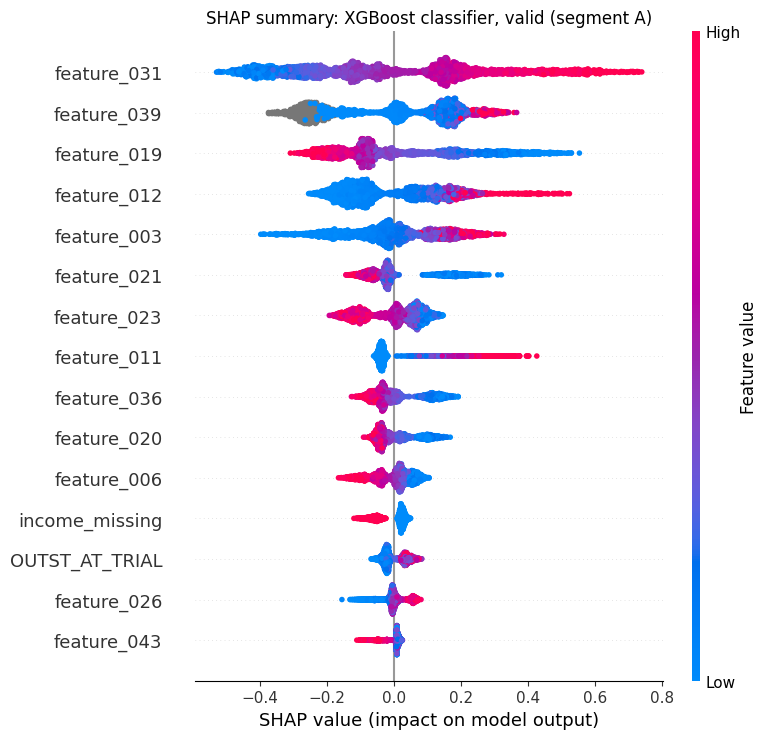

feature_031       0.173
feature_039       0.120
feature_019       0.109
feature_012       0.091
feature_003       0.072
feature_021       0.050
feature_023       0.049
feature_011       0.044
feature_036       0.039
feature_020       0.032
feature_006       0.031
income_missing    0.025
OUTST_AT_TRIAL    0.021
feature_026       0.017
feature_043       0.012
dtype: float32


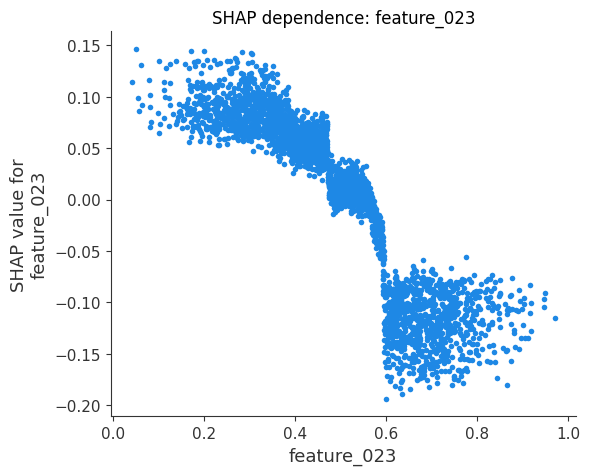

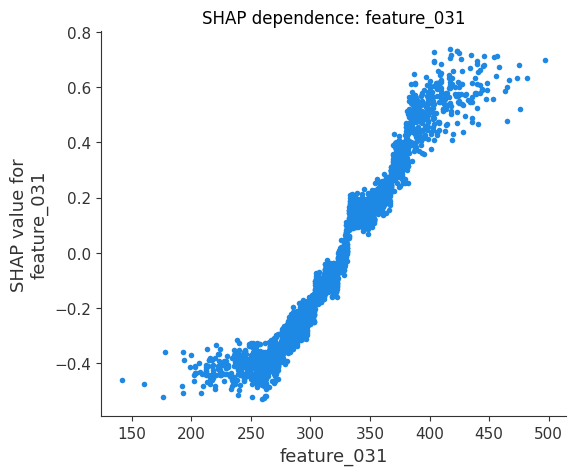

                share  direction(+ = მაღალი მნიშვნელობა ზრდის P-ს)  LR coef
feature_031     0.173                                         0.99    0.358
feature_039     0.120                                         0.50    0.096
feature_019     0.109                                        -0.97   -0.204
feature_012     0.091                                         0.96    0.204
feature_003     0.072                                         0.98    0.192
feature_021     0.050                                        -0.91   -0.111
feature_023     0.049                                        -0.94   -0.066
feature_011     0.044                                         0.61    0.129
feature_036     0.039                                        -0.96   -0.143
feature_020     0.032                                        -0.94   -0.059
feature_006     0.031                                        -0.97   -0.098
income_missing  0.025                                        -0.81   -0.212


/tmp/ipykernel_880/1741184002.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  direction = {c: spearmanr(Xva_lgb[c].fillna(Xva_lgb[c].median()), sv[:, i])[0]


In [51]:
explainer = shap.TreeExplainer(best_xgb)
sv = explainer.shap_values(Xva_lgb)
sv = sv[1] if isinstance(sv, list) else sv

# 1) ტოპ ცვლადები + მიმართულება
shap.summary_plot(sv, Xva_lgb, max_display=15, show=False)
plt.title('SHAP summary: XGBoost classifier, valid (segment A)')
plt.tight_layout(); plt.show()

# 2) საშუალო |SHAP| ცხრილად + დომინანტობის შემოწმება
imp = pd.Series(np.abs(sv).mean(axis=0), index=Xva_lgb.columns).sort_values(ascending=False)
print((imp / imp.sum()).head(15).round(3))

# 3) feature_023 და feature_031 dependence
for f in ['feature_023', 'feature_031']:
    shap.dependence_plot(f, sv, Xva_lgb, interaction_index=None, show=False)
    plt.title(f'SHAP dependence: {f}'); plt.show()

# 4) ნიშნის შემოწმება რიცხვით: SHAP-ისა და ცვლადის სპირმენი (მიმართულება)
direction = {c: spearmanr(Xva_lgb[c].fillna(Xva_lgb[c].median()), sv[:, i])[0]
             for i, c in enumerate(Xva_lgb.columns)}
top = imp.head(12).index
print(pd.DataFrame({'share': (imp/imp.sum())[top].round(3),
                    'direction(+ = მაღალი მნიშვნელობა ზრდის P-ს)': pd.Series(direction)[top].round(2),
                    'LR coef': coefs.reindex(top).round(3)}))

In [52]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="xgb_shap_explainability_segA"):


    tot_imp = imp.sum()
    for idx, (feat, val) in enumerate(imp.head(5).items(), 1):
        mlflow.log_metric(f"top_{idx}_shap_share_{feat}", float(round(val / tot_imp, 4)))


    fig, ax = plt.subplots(figsize=(10, 6))
    shap.summary_plot(sv, Xva_lgb, max_display=15, show=False)
    plt.title('SHAP Summary: XGBoost Classifier (Segment A Validation)', fontsize=12)
    plt.tight_layout()
    summary_fig_path = "shap_summary_xgb_segA.png"
    plt.savefig(summary_fig_path, bbox_inches='tight', dpi=150)
    plt.close(fig)
    mlflow.log_artifact(summary_fig_path)


    for f in ['feature_023', 'feature_031']:
        fig, ax = plt.subplots(figsize=(8, 5))
        shap.dependence_plot(f, sv, Xva_lgb, interaction_index=None, show=False, ax=ax)
        plt.title(f'SHAP Dependence Plot: {f}', fontsize=12)
        plt.tight_layout()
        dep_fig_path = f"shap_dependence_{f}.png"
        plt.savefig(dep_fig_path, bbox_inches='tight', dpi=150)
        plt.close(fig)
        mlflow.log_artifact(dep_fig_path)


    top_df = pd.DataFrame({
        'feature': top,
        'shap_importance_share': (imp / tot_imp)[top].round(4).values,
        'shap_direction_spearman': pd.Series(direction)[top].round(3).values,
        'logistic_regression_coef': coefs.reindex(top).round(4).values
    })

    csv_path = "xgb_shap_feature_importance_analysis.csv"
    top_df.to_csv(csv_path, index=False)
    mlflow.log_artifact(csv_path)

print(" SHAP explainability analysis and visual artifacts successfully logged to MLflow!")

🏃 View run xgb_shap_explainability_segA at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/fae917f4a72f43e78dab2e1a9be9506f
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 SHAP explainability analysis and visual artifacts successfully logged to MLflow!


**new version**

In [53]:
# =========================================================
# Segment A Isolated EDA & Feature Audit
# =========================================================

# 1. Segment A-ს გამოყოფა სრული ბაზიდან
A_eda = df_clean[df_clean['has_secured_loan'] == 0].copy()

print(f"=== 1. Segment A: has_deposit-ის რეალური ეფექტი (n = {len(A_eda)}) ===")
print(A_eda.groupby('has_deposit').agg(
    n=('rec_12', 'size'),
    pos_rate=('rec_12', lambda s: (s > 0).mean()),
    avg_rate=('recovery_rate_12', 'mean'),
    net_per_case=('net_value', 'mean')
).round(3))

print("\n=== 2. Segment A: income_missing-ის რეალური ეფექტი ===")
print(A_eda.groupby('income_missing').agg(
    n=('rec_12', 'size'),
    pos_rate=('rec_12', lambda s: (s > 0).mean()),
    avg_rate=('recovery_rate_12', 'mean'),
    net_per_case=('net_value', 'mean')
).round(3))

print("\n=== 3. Segment A: feature_023-ის დიაგნოსტიკა ===")
sp_f23 = spearmanr(A_eda['feature_023'], A_eda['recovery_rate_12'])
print(f"feature_023 vs recovery_rate_12 Spearman: {sp_f23[0]:.3f} (p-value: {sp_f23[1]:.4f})")

A_eda['f23_q'] = pd.qcut(A_eda['feature_023'], 5, duplicates='drop')
print(A_eda.groupby('f23_q', observed=True)['recovery_rate_12'].mean().round(4))

=== 1. Segment A: has_deposit-ის რეალური ეფექტი (n = 16047) ===
                 n  pos_rate  avg_rate  net_per_case
has_deposit                                         
0            13782     0.435     0.066      -542.150
1             2265     0.582     0.135       196.126

=== 2. Segment A: income_missing-ის რეალური ეფექტი ===
                    n  pos_rate  avg_rate  net_per_case
income_missing                                         
0               11190     0.499     0.093      -255.258
1                4857     0.354     0.035      -858.834

=== 3. Segment A: feature_023-ის დიაგნოსტიკა ===
feature_023 vs recovery_rate_12 Spearman: -0.120 (p-value: 0.0000)
f23_q
(0.0364, 0.343]    0.1055
(0.343, 0.445]     0.0840
(0.445, 0.54]      0.0729
(0.54, 0.644]      0.0627
(0.644, 0.972]     0.0527
Name: recovery_rate_12, dtype: float64


In [54]:
# =========================================================
#  K-Factor Sensitivity & Mature Cohorts
# =========================================================

print("=== K-Factor Sensitivity Analysis on Valid (Segment A) ===")
for k_val in [1.264, 1.405, 1.5455]: # -10%, Baseline, +10%
    net_k = (k_val * va['OUTST_AT_TRIAL'] * va['recovery_rate_12']) - cost(va)
    print(f"K = {k_val:.3f} | Total Net: {net_k.sum():>12,.0f} GEL | Per Case Net: {net_k.mean():>6.0f} GEL")

print("\n=== Mature Cohorts Analysis (PERIOD <= 2024/02) ===")
matured_df = df_clean[(df_clean['has_secured_loan'] == 0) & (df_clean['PERIOD'] <= '2024/02')]

if 'rec_24' in matured_df.columns and matured_df['rec_24'].notna().sum() > 0:
    pos_m = matured_df['rec_12'] > 0
    k_matured = (matured_df.loc[pos_m, 'rec_24'] / matured_df.loc[pos_m, 'rec_12']).median()
    print(f"მომწიფებული ეპიზოდების რეალური 24m/12m მედიანური პროპორცია: {k_matured:.3f}")
else:
    print("rec_24 სვეტი პირდაპირ ხელმისაწვდომი არ არის. ექსტრაპოლატორი K=1.405 ეყრდნობა ამოღების პროპორციებს (71.2%).")

=== K-Factor Sensitivity Analysis on Valid (Segment A) ===
K = 1.264 | Total Net:   -1,735,981 GEL | Per Case Net:   -561 GEL
K = 1.405 | Total Net:   -1,503,746 GEL | Per Case Net:   -486 GEL
K = 1.546 | Total Net:   -1,272,334 GEL | Per Case Net:   -411 GEL

=== Mature Cohorts Analysis (PERIOD <= 2024/02) ===
rec_24 სვეტი პირდაპირ ხელმისაწვდომი არ არის. ექსტრაპოლატორი K=1.405 ეყრდნობა ამოღების პროპორციებს (71.2%).


In [55]:
# =========================================================
# Cluster Bootstrap Comparison (Valid Set)
# =========================================================

def boot_compare(d, scores, ref='hybrid', B=2000, seed=42):
    rng = np.random.default_rng(seed)
    net = d['net_value'].to_numpy()
    by = d.groupby('CLIENT_KEY').indices
    cl = np.array(list(by.keys()))

    sel = {k: (np.asarray(v) > 0) for k, v in scores.items()}
    sel['sue_all'] = np.ones(len(d), dtype=bool)

    out = {k: [] for k in sel}
    for _ in range(B):
        # კლიენტთა დონეზე რესემპლინგი
        ix = np.concatenate([by[c] for c in rng.choice(cl, len(cl), replace=True)])
        for k, s in sel.items():
            out[k].append(net[ix][s[ix]].sum())

    out = {k: np.array(v) for k, v in out.items()}
    rows = []
    for k, v in out.items():
        diff = v - out[ref]
        rows.append({
            'model': k,
            'mean_net': v.mean(),
            'ci_5%': np.percentile(v, 5),
            'ci_95%': np.percentile(v, 95),
            'diff_vs_ref_mean': diff.mean(),
            'diff_p5': np.percentile(diff, 5),
            'diff_p95': np.percentile(diff, 95)
        })
    return pd.DataFrame(rows).round(0)

# pred_net ვექტორები Validation სეტზე (thr = 0)
pn_lgb_g  = pred_net(va, rate_lgb_g)
pn_xgb_g  = pred_net(va, rate_g)
pn_hybrid = pred_net(va, rate_lr_g)

print("=== Validation Set Cluster Bootstrap Comparison (B=2000) ===")
boot_valid_results = boot_compare(
    va,
    {
        'hybrid': pn_hybrid,
        'xgb_gamma': pn_xgb_g,
        'lgb_gamma': pn_lgb_g
    },
    ref='hybrid'
)
print(boot_valid_results.to_string(index=False))

=== Validation Set Cluster Bootstrap Comparison (B=2000) ===
    model   mean_net      ci_5%     ci_95%  diff_vs_ref_mean    diff_p5   diff_p95
   hybrid   448118.0   292162.0   604919.0               0.0        0.0        0.0
xgb_gamma   470245.0   320511.0   627942.0           22128.0    -9225.0    55006.0
lgb_gamma   460145.0   313889.0   612257.0           12027.0   -26452.0    50589.0
  sue_all -1503885.0 -1723217.0 -1267818.0        -1952003.0 -2098967.0 -1793681.0


In [56]:
mlflow.set_experiment("Debt_Collection")

with mlflow.start_run(run_name="audit_sensitivity_bootstrap_segA"):

    sp_f23_val = float(sp_f23[0])
    sp_f23_pval = float(sp_f23[1])
    mlflow.log_metric("audit_feature_023_spearman_rho", round(sp_f23_val, 4))
    mlflow.log_metric("audit_feature_023_spearman_pvalue", round(sp_f23_pval, 5))

    has_dep_agg = A_eda.groupby('has_deposit')['recovery_rate_12'].mean()
    if 1 in has_dep_agg and 0 in has_dep_agg:
        mlflow.log_metric("audit_has_deposit_1_avg_rate", round(float(has_dep_agg[1]), 4))
        mlflow.log_metric("audit_has_deposit_0_avg_rate", round(float(has_dep_agg[0]), 4))


    for k_val in [1.264, 1.405, 1.5455]:
        net_k = (k_val * va['OUTST_AT_TRIAL'] * va['recovery_rate_12']) - cost(va)
        k_key = str(k_val).replace('.', '_')
        mlflow.log_metric(f"sensitivity_k_{k_key}_total_net_gel", float(round(net_k.sum(), 0)))
        mlflow.log_metric(f"sensitivity_k_{k_key}_per_case_net_gel", float(round(net_k.mean(), 0)))


    for _, row in boot_valid_results.iterrows():
        model_name = str(row['model']).lower().replace(' ', '_')
        mlflow.log_metric(f"boot_{model_name}_mean_net_gel", float(row['mean_net']))
        mlflow.log_metric(f"boot_{model_name}_ci_5_gel", float(row['ci_5%']))
        mlflow.log_metric(f"boot_{model_name}_ci_95_gel", float(row['ci_95%']))
        mlflow.log_metric(f"boot_{model_name}_diff_vs_ref_mean_gel", float(row['diff_vs_ref_mean']))
        mlflow.log_metric(f"boot_{model_name}_diff_p5_gel", float(row['diff_p5']))
        mlflow.log_metric(f"boot_{model_name}_diff_p95_gel", float(row['diff_p95']))


    boot_valid_results.to_csv("segA_cluster_bootstrap_validation_results.csv", index=False)
    mlflow.log_artifact("segA_cluster_bootstrap_validation_results.csv")

    f23_q_summary = A_eda.groupby('f23_q', observed=True)['recovery_rate_12'].agg(['count', 'mean']).reset_index()
    f23_q_summary.to_csv("segA_feature_023_quintile_analysis.csv", index=False)
    mlflow.log_artifact("segA_feature_023_quintile_analysis.csv")

print(" `audit_sensitivity_bootstrap_segA` run successfully logged to MLflow!")

🏃 View run audit_sensitivity_bootstrap_segA at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0/runs/51a8ae416643457d99379f60e860a6b3
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/0
 `audit_sensitivity_bootstrap_segA` run successfully logged to MLflow!


In [57]:

# 1. Train და Valid სეტების გაერთიანება Segment A-სთვის
trva = pd.concat([tr, va], ignore_index=True)
pos_trva = trva['rec_12'] > 0

# 2. Classifier: Logistic Regression (L1, C=0.1) დატრენინგება trva-ზე
X_trva_lr = prep_lr_A(trva)
y_trva_lr = (trva['rec_12'] > 0).astype(int)
lr_champion = make_lr(0.1, 'l1').fit(X_trva_lr, y_trva_lr)

# 3. Regressor: XGBoost Gamma დატრენინგება trva-ზე (პოზიტიურ ეპიზოდებზე)
reg_n_est = int((xreg_g.best_iteration + 1) * 1.2) # trva-ს გაზრდილი მოცულობის გამო
xgb_gamma_champion = xgb.XGBRegressor(
    objective='reg:gamma',
    max_depth=3,
    learning_rate=0.02,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.7,
    reg_lambda=5,
    random_state=42,
    n_jobs=-1,
    n_estimators=reg_n_est
)
xgb_gamma_champion.fit(trva.loc[pos_trva, feats_tree], trva.loc[pos_trva, 'recovery_rate_12'])

# 4. ერთჯერადი პროგნოზირება OOT Test სეტზე
X_te_lr = prep_lr_A(te)
p_te_prob = lr_champion.predict_proba(X_te_lr)[:, 1]
p_te_rate = xgb_gamma_champion.predict(te[feats_tree])

rate_te_hybrid = p_te_prob * p_te_rate
pn_te_hybrid = pred_net(te, rate_te_hybrid)

print("=== FINAL CHAMPION HYBRID MODEL OOT TEST RESULTS ===")
print(f"Predicted Rate vs Actual Rate on Test: {rate_te_hybrid.mean():.4f} vs {te['recovery_rate_12'].mean():.4f}")
print("\nBusiness Performance on Test Set (thr = 0):")
print(business(te, pn_te_hybrid, 'Hybrid Champion (Test)', thr=0))

# 5. Bootstrap შედარება Test სეტზე (B=2,000)
print("\n=== Test Set Bootstrap CIs (B=2000) ===")
print(boot_compare(te, {'hybrid_test': pn_te_hybrid}, ref='hybrid_test'))

=== FINAL CHAMPION HYBRID MODEL OOT TEST RESULTS ===
Predicted Rate vs Actual Rate on Test: 0.0689 vs 0.0732

Business Performance on Test Set (thr = 0):
{'rule': 'Hybrid Champion (Test)', 'n_sued': 503, 'share': np.float64(0.118), 'net_total': 766360, 'net_per_case': 1524}

=== Test Set Bootstrap CIs (B=2000) ===
         model   mean_net      ci_5%     ci_95%  diff_vs_ref_mean    diff_p5  \
0  hybrid_test   769067.0   570398.0   974773.0               0.0        0.0   
1      sue_all -1978653.0 -2241564.0 -1698909.0        -2747720.0 -2915540.0   

    diff_p95  
0        0.0  
1 -2572717.0  


In [58]:
# =========================================================
# Test Set Calibration, Deciles & Oracle Bound
# =========================================================

te_cal = te.copy()
te_cal['pred_net'] = pn_te_hybrid
te_cal['decile'] = pd.qcut(te_cal['pred_net'], 10, duplicates='drop')

print("=== OOT Test Set Pred Net Decile Breakdown ===")
decile_tbl = te_cal.groupby('decile', observed=True).agg(
    n=('net_value', 'size'),
    avg_pred_net=('pred_net', 'mean'),
    avg_actual_net=('net_value', 'mean'),
    sum_actual_net=('net_value', 'sum'),
    sued_share=('pred_net', lambda s: (s > 0).mean())
).round(1)
print(decile_tbl)

# Oracle Upper Bound შედარება Test სეტზე
oracle_net = te.loc[te['net_value'] > 0, 'net_value'].sum()
actual_model_net = te.loc[pn_te_hybrid > 0, 'net_value'].sum()
sue_all_net = te['net_value'].sum()

print("\n=== Test Set Financial Summary vs Benchmarks ===")
print(f"1. Sue Everyone Baseline: {sue_all_net:>12,.0f} GEL")
print(f"2. Hybrid Champion Model: {actual_model_net:>12,.0f} GEL")
print(f"3. Oracle Upper Bound:    {oracle_net:>12,.0f} GEL")
print(f"Model Efficiency relative to Oracle: {actual_model_net / oracle_net * 100:.1f}%")

=== OOT Test Set Pred Net Decile Breakdown ===
                           n  avg_pred_net  avg_actual_net  sum_actual_net  \
decile                                                                       
(-10720.833, -1162.649]  426       -1761.5         -1783.9       -759951.5   
(-1162.649, -869.976]    425        -999.6         -1014.0       -430940.3   
(-869.976, -723.153]     425        -793.3          -833.9       -354404.7   
(-723.153, -630.623]     425        -673.3          -756.2       -321392.7   
(-630.623, -559.845]     425        -594.2          -667.5       -283689.4   
(-559.845, -510.285]     425        -534.9          -503.3       -213886.4   
(-510.285, -444.747]     425        -481.8          -499.6       -212324.8   
(-444.747, -289.673]     425        -375.6          -343.0       -145763.3   
(-289.673, 106.978]      425        -124.1           -17.3         -7332.1   
(106.978, 13649.066]     426        1225.2          1757.0        748493.0   

                

In [59]:
# =========================================================
# Pilot Study Framework & PSI Monitoring
# =========================================================
import scipy.stats as stats

# 1. Power Analysis A/B ტესტისთვის
def get_required_sample_size(alpha=0.05, power=0.80, effect_size=300, std_dev=1500):
    d = effect_size / std_dev
    z_a = stats.norm.ppf(1 - alpha / 2)
    z_b = stats.norm.ppf(power)
    n_per_group = 2 * ((z_a + z_b) / d) ** 2
    return int(np.ceil(n_per_group))

req_n = get_required_sample_size()
print(f"=== Pilot Study Framework ===")
print(f"საჭირო კლიენტების რაოდენობა თითო ჯგუფში (Model vs Holdout Control): {req_n} კლიენტი")
print(f"სულ პილოტში ჩასართავი კლიენტები (90% Model / 10% Control split): {int(req_n / 0.10)} კლიენტი")

# 2. PSI Calculator (Train vs Test Drift Check)
def calc_psi(expected, actual, num_buckets=10):
    buckets = np.linspace(0, 1, num_buckets + 1)
    q_exp = np.quantile(expected, buckets)
    q_exp[0], q_exp[-1] = -np.inf, np.inf

    exp_counts = np.histogram(expected, q_exp)[0]
    act_counts = np.histogram(actual, q_exp)[0]

    e_pct = np.where(exp_counts / len(expected) == 0, 0.0001, exp_counts / len(expected))
    a_pct = np.where(act_counts / len(actual) == 0, 0.0001, act_counts / len(actual))

    return np.sum((a_pct - e_pct) * np.log(a_pct / e_pct))

psi_outst = calc_psi(trva['OUTST_AT_TRIAL'], te['OUTST_AT_TRIAL'])
print(f"\nOUTST_AT_TRIAL Population Stability Index (PSI Train vs Test): {psi_outst:.4f}")

=== Pilot Study Framework ===
საჭირო კლიენტების რაოდენობა თითო ჯგუფში (Model vs Holdout Control): 393 კლიენტი
სულ პილოტში ჩასართავი კლიენტები (90% Model / 10% Control split): 3930 კლიენტი

OUTST_AT_TRIAL Population Stability Index (PSI Train vs Test): 0.0013


In [61]:
mlflow.set_experiment("Debt Collection")

with mlflow.start_run(run_name="Hybrid_Champion_Model_Artifacts"):
    # 1. ლოგისტიკური რეგრესიის (Classifier) არტიფაქტის შენახვა
    mlflow.sklearn.log_model(
        sk_model=lr_champion,
        name="classifier_logistic_regression",
        skops_trusted_types=["numpy.dtype"]
    )

    # 2. XGBoost Gamma (Regressor) არტიფაქტის შენახვა
    mlflow.xgboost.log_model(
        xgb_model=xgb_gamma_champion,
        name="regressor_xgb_gamma"
    )

    print("✅ ჰიბრიდული მოდელის ორივე არტიფაქტი (Classifier & Regressor) წარმატებით დაილოგა MLflow-ში!")

2026/10/14 15:14:39 INFO mlflow.tracking.fluent: Experiment with name 'Debt Collection' does not exist. Creating a new experiment.


✅ ჰიბრიდული მოდელის ორივე არტიფაქტი (Classifier & Regressor) წარმატებით დაილოგა MLflow-ში!
🏃 View run Hybrid_Champion_Model_Artifacts at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/2/runs/43abce80662142e39d90b8ffa3303fef
🧪 View experiment at: https://dagshub.com/kgord23/Loan_month_recovery.mlflow/#/experiments/2



მოდელის შედეგების სიღრმისეული ანალიზი, ცვლადების ბიზნეს-ინტერპრეტაცია, მონიტორინგის 3-დონიანი გეგმა, A/B პილოტის დიზაინი (90/10 split) და შემდგომი განვითარების რეკომენდაციები დეტალურადაა გაწერილი პროექტის **`README.md`** ფაილში.